# Predicting Representational Geometry — a minimal demonstration

**Claim.** The optimal code is the most compressed representation a *linear* readout can solve the task from. The object to factor is the **log-conditional** $L[\theta,x]=\log p(x\mid\theta)$ (centering it gives the PMI) — because a linear / bilinear readout produces **logits**, i.e. log-probabilities. Factoring it,
$$L[\theta,x]\;\approx\;E[\theta,k]\cdot D[k,x],$$
gives the **code** $E$ (the geometry) and the **decoder** $D$ (the readout features). Two settings: **co-occurrence statistics** (geometry read straight off the log-conditional) and **distributions** (decoder = sufficient statistic, code = natural parameters); then the **order-2 bilinear** case.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns  # registers the 'vlag' colormap
from numpy.polynomial.hermite_e import HermiteE
from scipy.stats import spearmanr
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

sns.set_theme(context="notebook", style="ticks")   # seaborn aesthetic; custom rcParams below override it
plt.rcParams.update({
    "figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11, "axes.titlesize": 12,
    "image.interpolation": "nearest",   # crisp heatmap cells (no anti-aliased blending)
})
rng = np.random.default_rng(0)


def eig_embed(S, k=2):
    """Top-k eigenvectors of a symmetric matrix, scaled by sqrt|eigenvalue| (classical MDS)."""
    w, V = np.linalg.eigh(S); o = np.argsort(w)[::-1]; w, V = w[o], V[:, o]
    return V[:, :k] * np.sqrt(np.abs(w[:k])), w


def double_center(K):
    """Double-center a square similarity matrix (the classical-MDS step)."""
    n = len(K); J = np.eye(n) - np.ones((n, n)) / n
    return J @ K @ J


def scatter2d(ax, fig, emb, c, *, cmap="twilight", title="", clabel="",
              xlabel="dim 1", ylabel="dim 2", path=None, close=True, annotate=False, s=60):
    """Consistent 2-D embedding scatter; path draws a connecting line (close=True for a ring)."""
    if path is not None:
        Q = emb[path]; Q = np.vstack([Q, Q[:1]]) if close else Q
        ax.plot(Q[:, 0], Q[:, 1], "-", color="lightgray", lw=1, zorder=0)
    sc = ax.scatter(emb[:, 0], emb[:, 1], c=c, cmap=cmap, s=s, zorder=2)
    if annotate:
        for i, (x, y) in enumerate(emb):
            ax.annotate(str(i), (x, y), fontsize=6, ha="center", va="center")
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel); ax.set_aspect("equal")
    fig.colorbar(sc, ax=ax, fraction=0.046, label=clabel)
    return sc


def cka(X, Y):
    """Linear CKA between two representations (rows = items)."""
    X = X - X.mean(0); Y = Y - Y.mean(0); Kx, Ky = X @ X.T, Y @ Y.T
    return (Kx * Ky).sum() / (np.linalg.norm(Kx) * np.linalg.norm(Ky))


def rsa(X, Y):
    """RSA: Spearman correlation of the two Euclidean RDMs (upper triangle)."""
    Dx = ((X[:, None] - X[None]) ** 2).sum(-1); Dy = ((Y[:, None] - Y[None]) ** 2).sum(-1)
    iu = np.triu_indices(len(X), 1)
    return spearmanr(Dx[iu], Dy[iu]).statistic

## The core picture

Rows = items (words, tokens, distributions — anything we take a sufficient statistic of); columns = outcomes; entries $\log p(x\mid\theta)$. The **left factor is the representation** (the geometry we plot); the **right factor is the readout** (the features applied to outcomes).

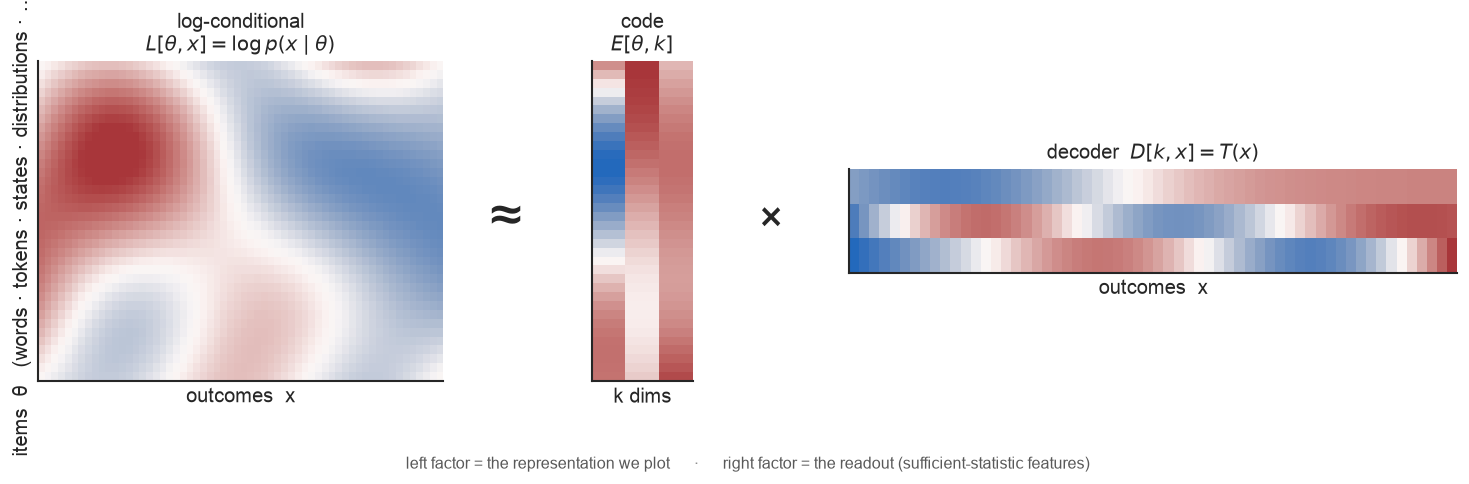

In [2]:
# a representative (low-rank, smooth) log-conditional and its code × decoder factorization
n_, m_ = 36, 60; ti = np.linspace(0, 1, n_); tj = np.linspace(0, 1, m_)
U = np.stack([np.sin(np.pi * ti), np.sin(2 * np.pi * ti), np.cos(np.pi * ti)], 1)
V = np.stack([np.cos(np.pi * tj), np.sin(2 * np.pi * tj), np.sin(3 * np.pi * tj)], 1)
Ldemo = (U * np.array([1.0, 0.6, 0.4])) @ V.T                 # log p(x|θ): a smooth rank-3 field
Uh, Sh, Vth = np.linalg.svd(Ldemo, full_matrices=False); kk = 3
Ehero, Dhero = Uh[:, :kk] * Sh[:kk], Vth[:kk]

fig = plt.figure(figsize=(13, 4.3)); fig.set_constrained_layout(False)
axP = fig.add_axes([0.045, 0.20, 0.26, 0.62]); axE = fig.add_axes([0.40, 0.20, 0.065, 0.62])
axD = fig.add_axes([0.565, 0.41, 0.39, 0.20])
v = np.percentile(np.abs(Ldemo), 98)
axP.imshow(Ldemo, aspect="auto", cmap="vlag", vmin=-v, vmax=v)
axE.imshow(Ehero, aspect="auto", cmap="vlag"); axD.imshow(Dhero, aspect="auto", cmap="vlag")
for a in (axP, axE, axD):
    a.set_xticks([]); a.set_yticks([])
axP.set_title("log-conditional\n$L[\\theta,x]=\\log p(x\\mid\\theta)$"); axE.set_title("code\n$E[\\theta,k]$")
axD.set_title("decoder  $D[k,x]=T(x)$")
axP.set_ylabel("items  θ   (words · tokens · states · distributions · …)"); axP.set_xlabel("outcomes  x")
axE.set_xlabel("k dims"); axD.set_xlabel("outcomes  x")
fig.text(0.345, 0.51, "≈", fontsize=34, ha="center", va="center")
fig.text(0.515, 0.51, "×", fontsize=26, ha="center", va="center")
fig.text(0.5, 0.03, "left factor = the representation we plot      ·      "
                    "right factor = the readout (sufficient-statistic features)",
         ha="center", fontsize=9.5, color="0.35")
plt.show()

## 1. Co-occurrence → a manifold

Items and outcomes are the *same* tokens, so the matrix is symmetric: **code = decoder**, and the geometry is read straight off the **log-conditional** by eigendecomposition (classical MDS; double-centering it = the **PMI**, what word2vec/GloVe factorize). The generating process is a graded kernel on a latent manifold, $p(\text{neighbor}\mid\text{point})\propto e^{\kappa\,\langle\cdot,\cdot\rangle}$; its symmetry sets the harmonics — a **ring** (translation) → Fourier → a circle; a **sphere** (rotation) → spherical harmonics → a sphere.

In [3]:
def cooccur_logcond(points, kappa):
    """Graded co-occurrence kernel on a manifold -> symmetric log-conditional."""
    P = np.exp(kappa * (points @ points.T)); P /= P.sum(1, keepdims=True)   # p(neighbor | point)
    L = np.log(P + 1e-12)                                                    # log-conditional (centering it = PMI)
    return 0.5 * (L + L.T)


def show_manifold(name, PMI, k, color, clabel, *, sort=None, cmap="twilight", path=None):
    emb, spec = eig_embed(double_center(PMI), k)
    cv = np.linalg.norm(emb, axis=1); cv = cv.std() / cv.mean()
    fig = plt.figure(figsize=(13, 3.9))
    axM = fig.add_subplot(1, 3, 1); axS = fig.add_subplot(1, 3, 2)
    o = np.argsort(sort) if sort is not None else np.arange(len(PMI))
    lim = np.abs(PMI).max()
    im = axM.imshow(PMI[np.ix_(o, o)], cmap="vlag", vmin=-lim, vmax=lim); fig.colorbar(im, ax=axM, fraction=0.046)
    axM.set(title=f"{name}: log-conditional", xlabel="point", ylabel="point")
    axS.plot(spec[:12], "o-", color="#333"); axS.axhline(0, color="gray", lw=0.6)
    axS.set(title="centered-log-cond. spectrum", xlabel="component", ylabel="eigenvalue")
    if k == 2:
        axE = fig.add_subplot(1, 3, 3)
        scatter2d(axE, fig, emb, color, cmap=cmap, clabel=clabel, title=f"{name}: embedding", path=path)
    else:
        axE = fig.add_subplot(1, 3, 3, projection="3d"); u = emb / np.linalg.norm(emb, axis=1, keepdims=True)
        sc = axE.scatter(u[:, 0], u[:, 1], u[:, 2], c=color, cmap=cmap, s=12)
        axE.set_title(f"{name}: embedding"); fig.colorbar(sc, ax=axE, fraction=0.04, label=clabel, pad=0.08)
    plt.tight_layout(); plt.show()
    print(f"{name}: top eigenvalues {spec[:6].round(1)}  |  embedding radius cv {cv:.4f} (~0 => on the manifold)")

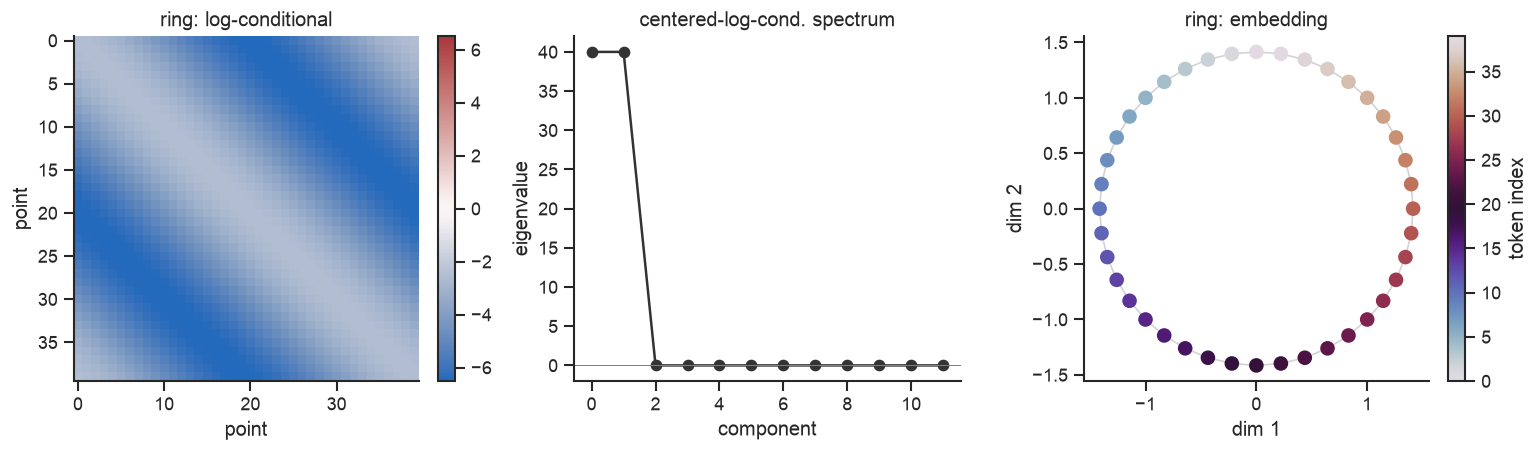

ring: top eigenvalues [40. 40.  0.  0.  0.  0.]  |  embedding radius cv 0.0000 (~0 => on the manifold)


In [4]:
# ring: translation symmetry -> Fourier -> circle
p = 40; th = 2 * np.pi * np.arange(p) / p
ring = np.stack([np.cos(th), np.sin(th)], 1)
show_manifold("ring", cooccur_logcond(ring, 2.0), 2, np.arange(p), "token index", path=np.arange(p))

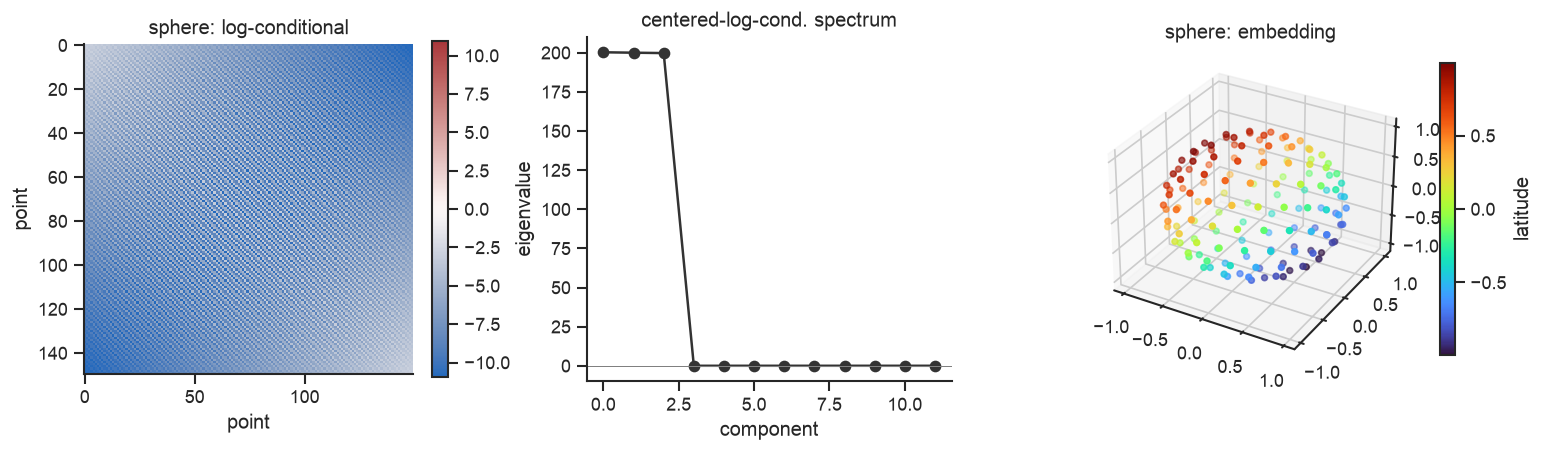

sphere: top eigenvalues [200.3 200.  199.7   0.    0.    0. ]  |  embedding radius cv 0.0002 (~0 => on the manifold)


In [5]:
# sphere: rotation symmetry -> spherical harmonics -> sphere (Fibonacci points)
Ns = 150; idx = np.arange(Ns); gold = np.pi * (1 + 5 ** 0.5)
zc = 1 - 2 * (idx + 0.5) / Ns; rc = np.sqrt(1 - zc ** 2); ph = gold * idx
sphere = np.stack([rc * np.cos(ph), rc * np.sin(ph), zc], 1)
show_manifold("sphere", cooccur_logcond(sphere, 4.0), 3, zc, "latitude", sort=zc, cmap="turbo")

Both recover the latent manifold exactly: the ring is **rank 2** (the $\pm1$ Fourier pair) and lands on a circle; the sphere is **rank 3** (the degree-1 harmonics $x,y,z$) and lands on a sphere. Translation vs rotation symmetry picks Fourier vs spherical harmonics — the geometry is set by the symmetry of the generating process.

## 2. Distributions → sufficient statistic × natural parameters

Now items are **distributions** and outcomes are the values $x$; the matrix is rectangular, so **code ≠ decoder**. Geometry lives in **log**-space, so we factor the *centered* log-conditional (centering removes the partition function and base measure), weighting columns by the marginal $\nu(x)$. The decoder $D$ comes out as the family's **sufficient statistic** $T(x)$; the code $E$ as its **natural parameters** $\eta(\theta)$. We check three families against their known $T(x)$; the code's intrinsic dimension is its rank, so we plot it in 2-D or 3-D accordingly.

In [6]:
def factor_logcond(Llog):
    """Centered, marginal-weighted SVD of a log-conditional -> code E, decoder D."""
    N, M = Llog.shape; w = np.full(N, 1.0 / N)
    pp = np.exp(Llog - Llog.max(1, keepdims=True)); pp /= pp.sum(1, keepdims=True)
    nu = pp.mean(0); nu /= nu.sum()                       # natural column measure (marginal)
    Lc = Llog - (w @ Llog)[None, :]                       # drop x-only term (base measure)
    Lc = Lc - (Lc @ nu)[:, None]                          # drop theta-only term (log-partition)
    U, S, Vt = np.linalg.svd(np.sqrt(w)[:, None] * Lc * np.sqrt(nu)[None, :], full_matrices=False)
    return Lc, (U / np.sqrt(w)[:, None]) * S, Vt / np.sqrt(nu)[None, :], S, nu


def _procrustes(src, tgt):
    """Orthogonal + uniform-scale alignment of src onto tgt; returns aligned src and R²."""
    a = src - src.mean(0); b = tgt - tgt.mean(0)
    U, Sv, Vt = np.linalg.svd(a.T @ b); R = U @ Vt; s = Sv.sum() / (a ** 2).sum()
    al = s * a @ R + tgt.mean(0)
    return al, 1 - ((al - tgt) ** 2).sum() / (b ** 2).sum()


def _geom(ax, emb, color, label, cmap, mesh, dim3, header=None):
    d = emb.shape[1]
    if mesh is not None:
        G = emb.reshape(*mesh, d)
        for r in range(mesh[0]):
            ax.plot(*[G[r, :, j] for j in range(d)], color="lightgray", lw=0.4, zorder=0)
        for c in range(mesh[1]):
            ax.plot(*[G[:, c, j] for j in range(d)], color="lightgray", lw=0.4, zorder=0)
    sc = ax.scatter(*[emb[:, j] for j in range(d)], c=color, cmap=cmap, s=15, zorder=2)
    if dim3:
        R = np.abs(emb).max() * 1.05
        ax.set_xlim(-R, R); ax.set_ylim(-R, R); ax.set_zlim(-R, R); ax.view_init(elev=24, azim=-60)
        ax.set_xticklabels([]); ax.set_yticklabels([]); ax.set_zticklabels([])
        ax.text2D(0.0, 0.92, label, transform=ax.transAxes, fontsize=9, color="0.35")
    else:
        ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
        ax.text(0.03, 0.90, label, transform=ax.transAxes, fontsize=9, color="0.35")
    if header:
        ax.set_title(header, fontsize=10)
    return sc


def show_dist(name, Llog, outcome, analytic, fnames, code_an, color, clabel, *,
              grid_shape=None, cmap="coolwarm", flat=False, dim3=False):
    k = len(analytic); gd = 3 if dim3 else 2
    Lc, E, D, S, nu = factor_logcond(Llog)
    embE, _ = eig_embed(double_center(E[:, :k] @ E[:, :k].T), gd)              # empirical code geometry
    embA, _ = eig_embed(double_center(code_an @ code_an.T), gd)               # analytic natural-param geometry
    embA, gr2 = _procrustes(embA, embE)                                       # align analytic onto empirical
    A = np.vstack(analytic); A = A - (A * nu).sum(1, keepdims=True); Dk = D[:k]
    W = (A * nu) @ Dk.T @ np.linalg.inv((Dk * nu) @ Dk.T + 1e-9 * np.eye(k)); Dal = W @ Dk
    r2 = 1 - ((A - Dal) ** 2 * nu).sum() / ((A ** 2 * nu).sum())

    fig = plt.figure(figsize=(13, 5.2), constrained_layout=True); proj = "3d" if dim3 else None
    gs = fig.add_gridspec(2, 3, width_ratios=[1.35, 0.7, 1.35])
    ax0 = fig.add_subplot(gs[:, 0])
    axE = fig.add_subplot(gs[0, 1], projection=proj); axA = fig.add_subplot(gs[1, 1], projection=proj)
    ax2 = fig.add_subplot(gs[:, 2])
    vmax = np.percentile(np.abs(Lc), 97)
    im = ax0.imshow(Lc, aspect="auto", cmap="vlag", vmin=-vmax, vmax=vmax); fig.colorbar(im, ax=ax0, fraction=0.046)
    ax0.set(title=f"{name}: log-conditional  L[theta,x]",
            xlabel="outcome x" + (" (flattened)" if flat else ""), ylabel="item theta")
    scE = _geom(axE, embE, color, "empirical", cmap, grid_shape, dim3,
                header=f"code  vs  natural params   (R²={gr2:.2f})")
    _geom(axA, embA, color, "analytic  η(θ)", cmap, grid_shape, dim3)
    fig.colorbar(scE, ax=[axE, axA], fraction=0.045, label=clabel)
    un = lambda f: (lambda g: g / np.sqrt((g * g * nu).sum()))(f - (f * nu).sum())
    t = np.arange(len(outcome)) if flat else outcome; cols = plt.cm.tab10(np.arange(k))
    for j in range(k):
        ax2.plot(t, un(A[j]), "--", color="k", lw=2, alpha=0.55)
        ax2.plot(t, un(Dal[j]), color=cols[j], lw=1.6, label=f"$D_{{{j+1}}}$ ~ {fnames[j]}")
    ax2.set(title=f"decoder vs analytic  (R²={r2:.3f})",
            xlabel="outcome" + (" (flattened)" if flat else " x")); ax2.legend()
    plt.show()
    print(f"{name}: spectrum {np.round(S[:5] / S[:5].sum(), 3)}  |  decoder R² {r2:.4f}  |  code vs natural-params R² {gr2:.4f}")

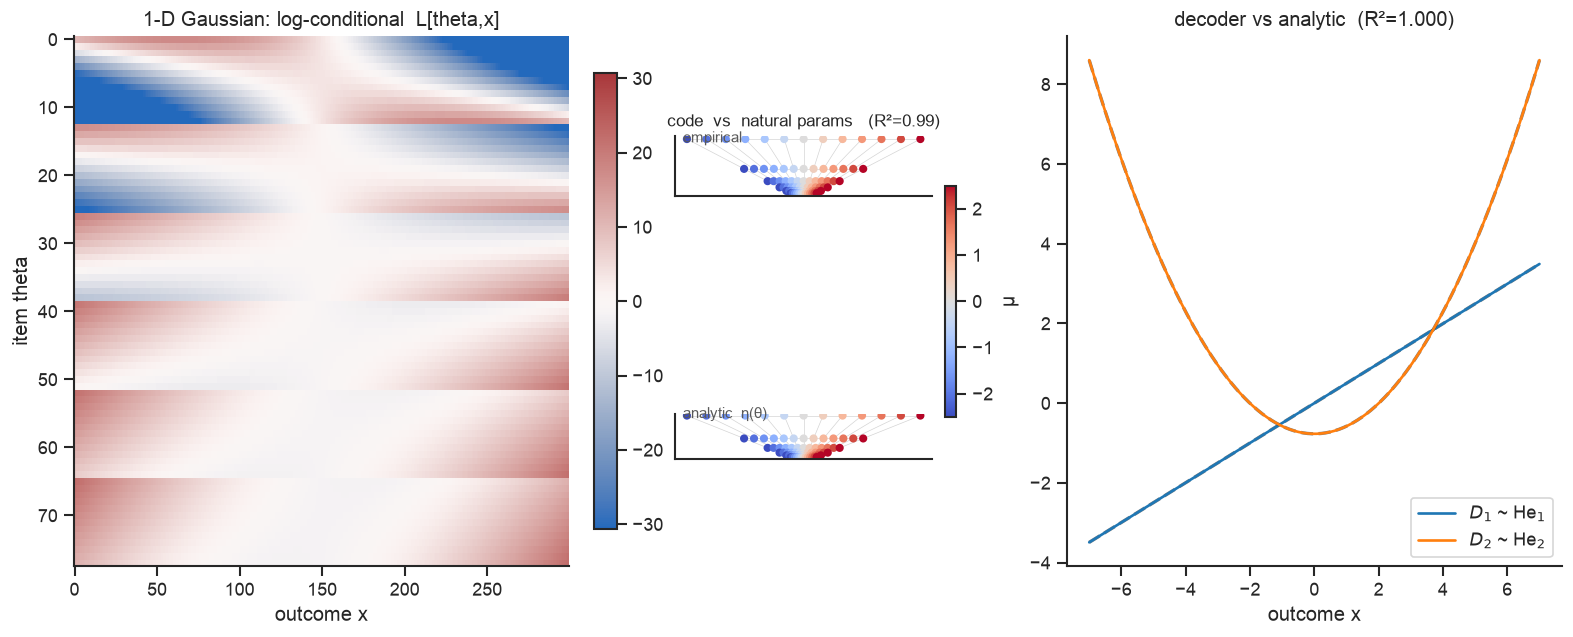

1-D Gaussian: spectrum [0.656 0.344 0.    0.    0.   ]  |  decoder R² 1.0000  |  code vs natural-params R² 0.9899


In [7]:
# 1-D Gaussian N(μ, σ): T=(x, x²) -> Hermite; natural params η=(μ/σ², 1/σ²)
n_mu, n_sig = 13, 6
mus = np.linspace(-2.5, 2.5, n_mu); sigs = np.linspace(0.6, 1.8, n_sig)
g = np.array([(m, s) for s in sigs for m in mus]); xs = np.linspace(-7, 7, 300)
Lg = -0.5 * ((xs[None] - g[:, 0:1]) / g[:, 1:2]) ** 2 - np.log(g[:, 1:2])
_, _, _, _, nug = factor_logcond(Lg); tau = np.sqrt((nug * xs ** 2).sum() - (nug * xs).sum() ** 2)
He = lambda d: HermiteE(np.eye(d + 1)[d])(xs / tau)
eta = np.stack([g[:, 0] / g[:, 1] ** 2, 1.0 / g[:, 1] ** 2], 1)
show_dist("1-D Gaussian", Lg, xs, [He(1), He(2)], ["He$_1$", "He$_2$"], eta, g[:, 0], "μ", grid_shape=(n_sig, n_mu))

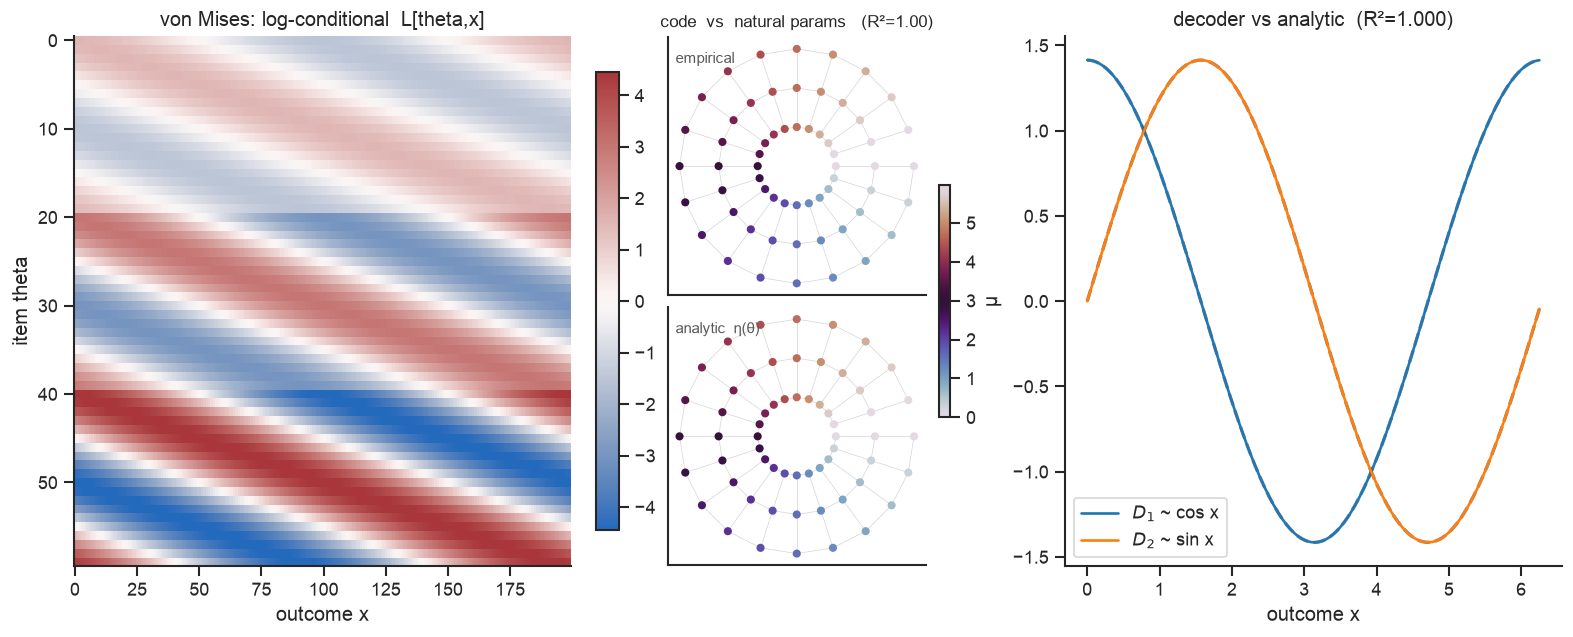

von Mises: spectrum [0.5 0.5 0.  0.  0. ]  |  decoder R² 1.0000  |  code vs natural-params R² 1.0000


In [8]:
# von Mises p∝exp(κ cos(x-μ)): T=(cos x, sin x); natural params η=(κcos μ, κsin μ)
n_m2, n_k = 20, 3
mu2 = np.linspace(0, 2 * np.pi, n_m2, endpoint=False); kaps = np.array([1.5, 3.0, 4.5])
gv = np.array([(m, k) for k in kaps for m in mu2]); xa = np.linspace(0, 2 * np.pi, 200, endpoint=False)
Lv = gv[:, 1:2] * np.cos(xa[None] - gv[:, 0:1])
etav = np.stack([gv[:, 1] * np.cos(gv[:, 0]), gv[:, 1] * np.sin(gv[:, 0])], 1)
show_dist("von Mises", Lv, xa, [np.cos(xa), np.sin(xa)], ["cos x", "sin x"], etav, gv[:, 0], "μ",
          grid_shape=(n_k, n_m2), cmap="twilight")

/Users/danielwurgaft/Documents/obsidian-vault/08 Projects/Predicting Representational Geometry/.venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


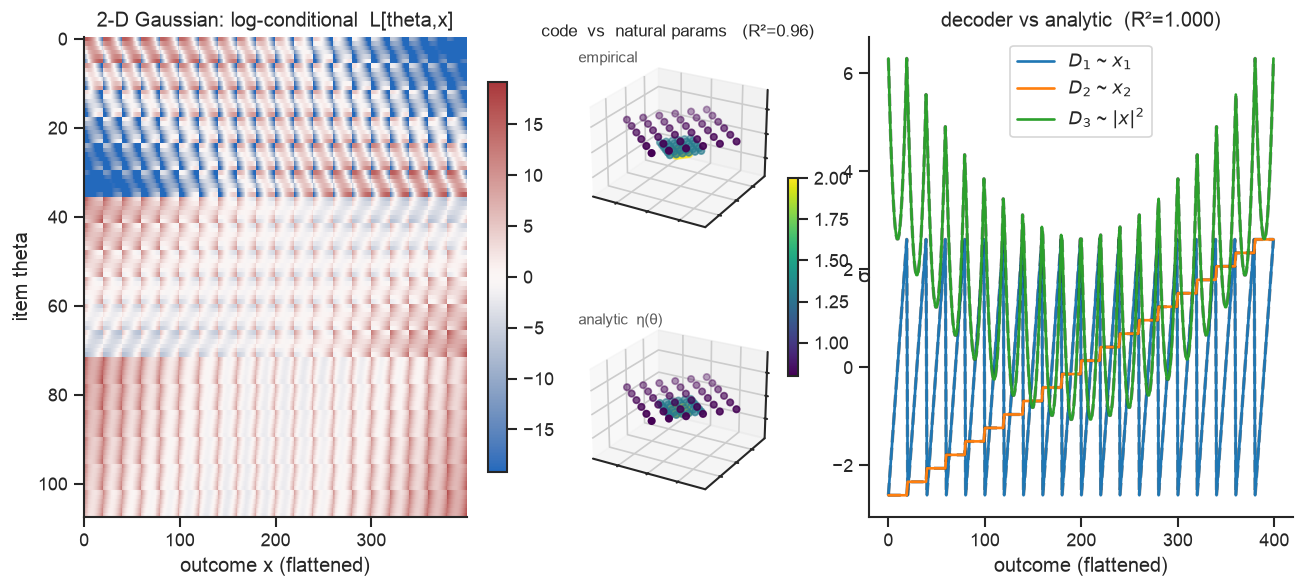

2-D Gaussian: spectrum [0.365 0.365 0.269 0.    0.   ]  |  decoder R² 1.0000  |  code vs natural-params R² 0.9630


In [9]:
# 2-D Gaussian N(μ, σ²I), varying (μ₁,μ₂,σ): T=(x₁,x₂,|x|²); natural params η=(μ₁/σ²,μ₂/σ²,1/σ²)
nm = 6; mm = np.linspace(-2, 2, nm); ss = np.array([0.8, 1.3, 2.0])
mus2 = np.array([(a, b, s) for s in ss for b in mm for a in mm])
m = 20; a1 = np.linspace(-5, 5, m); X1, X2 = np.meshgrid(a1, a1); xy = np.stack([X1.ravel(), X2.ravel()], 1)
L2 = -0.5 * ((xy[None, :, :] - mus2[:, None, :2]) ** 2).sum(-1) / mus2[:, None, 2] ** 2 - np.log(mus2[:, 2:3])
eta2 = np.stack([mus2[:, 0] / mus2[:, 2] ** 2, mus2[:, 1] / mus2[:, 2] ** 2, 1.0 / mus2[:, 2] ** 2], 1)
show_dist("2-D Gaussian", L2, xy, [xy[:, 0], xy[:, 1], (xy ** 2).sum(1)], ["$x_1$", "$x_2$", "$|x|^2$"],
          eta2, mus2[:, 2], "σ", cmap="viridis", flat=True, dim3=True)

Each decoder matches the analytic sufficient statistic exactly (**R² = 1**): Gaussian → Hermite $(x, x^2)$, von Mises → Fourier $(\cos x, \sin x)$, 2-D Gaussian → $(x_1, x_2, |x|^2)$. And the recovered **code** (empirical, top) matches the closed-form **natural-parameter manifold** (analytic, bottom) up to a similarity transform (R² ≥ 0.96): the 1-D Gaussian's $(\mu/\sigma^2, 1/\sigma^2)$ — a flat, anisotropic fan (sharp distributions flung out); von Mises' $(\kappa\cos\mu, \kappa\sin\mu)$ — a flat annulus; the 2-D Gaussian's $(\mu_1/\sigma^2, \mu_2/\sigma^2, 1/\sigma^2)$ — a curved 3-D surface. The code's dimension equals the number of free parameters — the distribution analogue of flat-circle vs curved-sphere.

## 3. Order-2: combination → a tensor, decoded bilinearly

When the target depends on **two** inputs, the conditional is a **tensor** $p(c\mid a,b)$, and a linear readout can't combine two codes. The readout becomes **bilinear**,
$$\text{logit}_c(a,b) = e(a)^\top M_c\, e(b),$$
a single shared code $e(\cdot)$ applied to both inputs, contracted by a per-output readout $M_c$. The hero below shows the tensor and this decomposition; then we train it from scratch on modular addition.

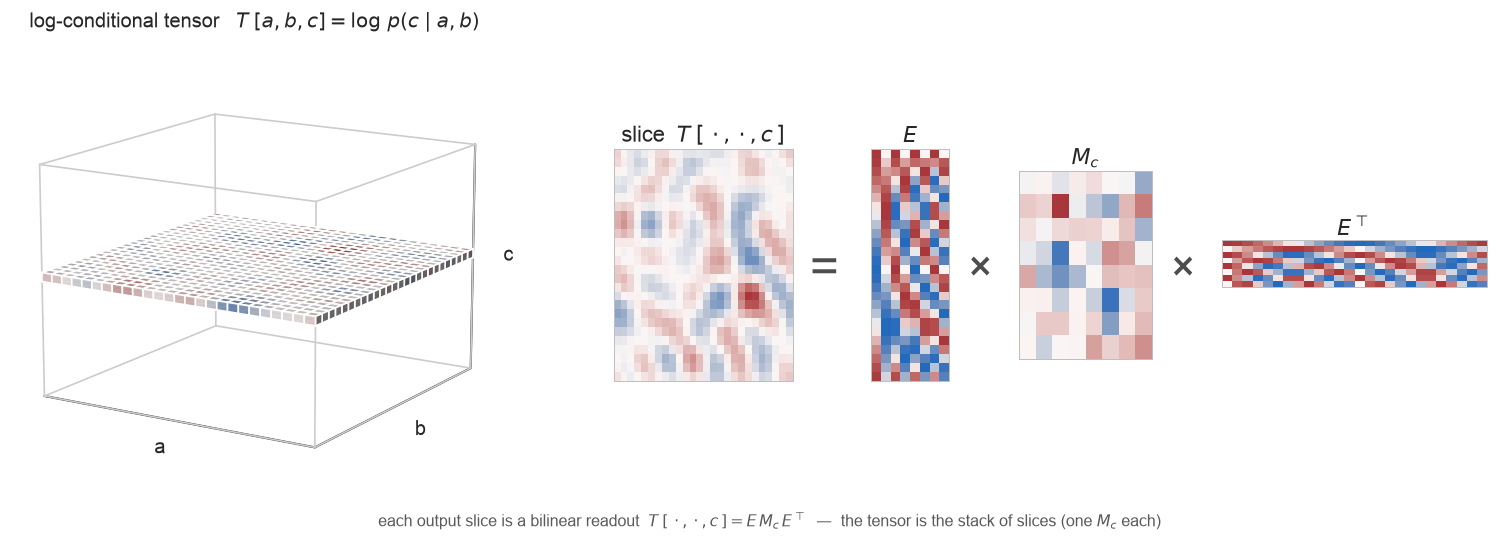

In [10]:
# bilinear hero: one slice of the log-conditional tensor, deconstructed as E · M_c · Eᵀ
import itertools
from matplotlib import cm
from matplotlib.colors import TwoSlopeNorm
n_, nc_, k_ = 26, 26, 8; tok = np.arange(n_); th = 2 * np.pi * tok / n_
Eg = np.stack([f(j * th) for j in range(1, k_ // 2 + 1) for f in (np.cos, np.sin)], 1)   # smooth code
Mg = np.random.default_rng(1).standard_normal((k_, k_, nc_))
T3 = np.einsum("ai,ijc,bj->abc", Eg, Mg, Eg); c0 = 13; sl = T3[:, :, c0]

fig = plt.figure(figsize=(13, 4.6)); fig.set_constrained_layout(False)
axT = fig.add_axes([0.0, 0.05, 0.34, 0.88], projection="3d")
pts = np.array(list(itertools.product([0, n_], [0, n_], [0, nc_])))            # cube outline only
for u, v in [(0,1),(0,2),(0,4),(1,3),(1,5),(2,3),(2,6),(3,7),(4,5),(4,6),(5,7),(6,7)]:
    axT.plot(*zip(pts[u], pts[v]), color="0.8", lw=1.0)
filled = np.zeros(T3.shape, bool); filled[:, :, c0] = True                     # one highlighted slice
fc = np.zeros(T3.shape + (4,))
fc[:, :, c0, :3] = plt.get_cmap("vlag")(TwoSlopeNorm(0, T3.min(), T3.max())(sl))[..., :3]; fc[:, :, c0, 3] = 0.97
axT.voxels(filled, facecolors=fc, edgecolor=None)
axT.set_xlim(0, n_); axT.set_ylim(0, n_); axT.set_zlim(0, nc_)
axT.set_title("log-conditional tensor   $T\\;[a,b,c]=\\log\\,p(c\\mid a,b)$", fontsize=12, pad=-2)
axT.set_xlabel("a", labelpad=-8); axT.set_ylabel("b", labelpad=-8); axT.set_zlabel("c", labelpad=-8)
axT.set_xticks([]); axT.set_yticks([]); axT.set_zticks([])
for pn in (axT.xaxis, axT.yaxis, axT.zaxis):
    pn.pane.set_facecolor((1, 1, 1, 0)); pn.pane.set_edgecolor((1, 1, 1, 0))
axT.view_init(elev=14, azim=-58); axT.text(n_ / 2, n_ / 2, c0 + 1.5, "slice $c$", color="#b03050", fontsize=10)

def _show(ax, A, t, pad=4):
    L = np.abs(A).max(); ax.imshow(A, cmap="vlag", vmin=-L, vmax=L, aspect="auto")
    for s in ax.spines.values():
        s.set_visible(True); s.set_color("0.75"); s.set_linewidth(0.6)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(t, fontsize=13, pad=pad)
axS = fig.add_axes([0.40, 0.30, 0.115, 0.42]); _show(axS, sl, "slice  $T\\;[\\,\\cdot,\\cdot,c\\,]$")
axEa = fig.add_axes([0.565, 0.30, 0.05, 0.42]); _show(axEa, Eg, "$E$")
axM = fig.add_axes([0.66, 0.34, 0.085, 0.34]); _show(axM, Mg[:, :, c0], "$M_c$")
axEb = fig.add_axes([0.79, 0.47, 0.17, 0.085]); _show(axEb, Eg.T, "$E^\\top$", pad=2)
fig.text(0.535, 0.5, "=", fontsize=30, ha="center", va="center", color="0.3")
fig.text(0.635, 0.5, "×", fontsize=26, ha="center", va="center", color="0.3")
fig.text(0.765, 0.5, "×", fontsize=26, ha="center", va="center", color="0.3")
fig.text(0.5, 0.035, "each output slice is a bilinear readout  $T\\;[\\,\\cdot,\\cdot,c\\,]=E\\,M_c\\,E^\\top$  —  "
                     "the tensor is the stack of slices (one $M_c$ each)", ha="center", fontsize=9.5, color="0.35")
plt.show()

### Modular addition — train the bilinear model → circle

Now arity 2: the target $c=(a+b)\bmod p$ is a function of **two** separately-encoded inputs. A linear readout can't combine two embeddings, so we use the **bilinear** readout from the doc,
$$\text{logit}_c(a,b) = e(a)^\top M_c\, e(b),$$
and train a free embedding table $e$ and readout tensor $M$ with the **softmax loss + weight decay** — nothing else, no architecture.

**Why a circle, and why we must fit.** The conditional $\mathbb 1[a+b=c]$ is *deterministic*; its tensor's DFT is **flat** (equal weight at every frequency), so a variance/rank criterion can't rank the modes — there is no closed-form geometry to read off. Instead the **softmax loss demands a sharp correct logit (margin)** while **weight decay charges for it (rate)**; their equilibrium is the max-margin solution (Soudry et al. 2018), which on this task is a **sparse set of Fourier frequencies** (Nanda, Gromov, Morwani). Each surviving frequency $k$ maps the tokens to a **circle** $e(n)\propto(\cos 2\pi k n/p,\ \sin 2\pi k n/p)$ — turning *addition* into *rotation*. The rate pressure (weight decay) controls how many frequencies survive.

In [11]:
p = 11        
d = 10         # embedding dim (a few frequency-pairs of headroom)
steps = 5000
wd = 5.0      # rate pressure: high enough to sparsify to one frequency, low enough to still fit
lr = 5e-3
torch.manual_seed(1)

A, B = torch.meshgrid(torch.arange(p), torch.arange(p), indexing="ij")
a, b = A.reshape(-1), B.reshape(-1)
target = (a + b) % p                                       # MODULAR ADDITION:  c = (a + b) mod p

E = torch.nn.Parameter(torch.randn(p, d) * 0.3)
M = torch.nn.Parameter(torch.randn(p, d, d) * 0.3)
opt = torch.optim.AdamW([E, M], lr=lr, weight_decay=wd)

hist = []
for t in range(steps):
    opt.zero_grad()
    logits = torch.einsum("nd,cde,ne->nc", E[a], M, E[b])   # logit_c(a,b) = e(a) . M_c . e(b)
    loss = torch.nn.functional.cross_entropy(logits, target)
    loss.backward(); opt.step()
    if t % 50 == 0 or t == steps - 1:
        acc = (logits.argmax(1) == target).float().mean().item()
        hist.append((t, loss.item(), acc))
hist = np.array(hist)
print(f"final loss {hist[-1,1]:.4f}, accuracy {hist[-1,2]:.3f}")

final loss 1.9454, accuracy 1.000


In [12]:
emb = E.detach().numpy()
embc = emb - emb.mean(0)

# 2D view via PCA (top-2 singular directions of the embedding)
U, Sv, _ = np.linalg.svd(embc, full_matrices=False)
pcs = U[:, :2] * Sv[:2]

# frequency content: power per DFT frequency, summed over embedding columns
Fpow = (np.abs(np.fft.rfft(embc, axis=0)) ** 2).sum(1)[1:]
Fpow /= Fpow.sum()
k = int(np.argmax(Fpow)) + 1                               # dominant frequency (a gauge choice)

# analytic prediction: single-frequency circle at the selected frequency
nn = np.arange(p)
circle = np.stack([np.cos(2 * np.pi * k * nn / p), np.sin(2 * np.pi * k * nn / p)], 1)

print(f"embedding singular values: {Sv.round(2)}")
print(f"dominant frequency k={k} (power {Fpow[k-1]:.2f} of total)")
print(f"learned vs analytic circle:  CKA={cka(embc, circle):.4f}   RSA(Spearman)={rsa(embc, circle):.4f}")

embedding singular values: [1.45 1.45 0.19 0.07 0.02 0.01 0.   0.   0.   0.  ]
dominant frequency k=2 (power 0.99 of total)
learned vs analytic circle:  CKA=0.9997   RSA(Spearman)=0.9647


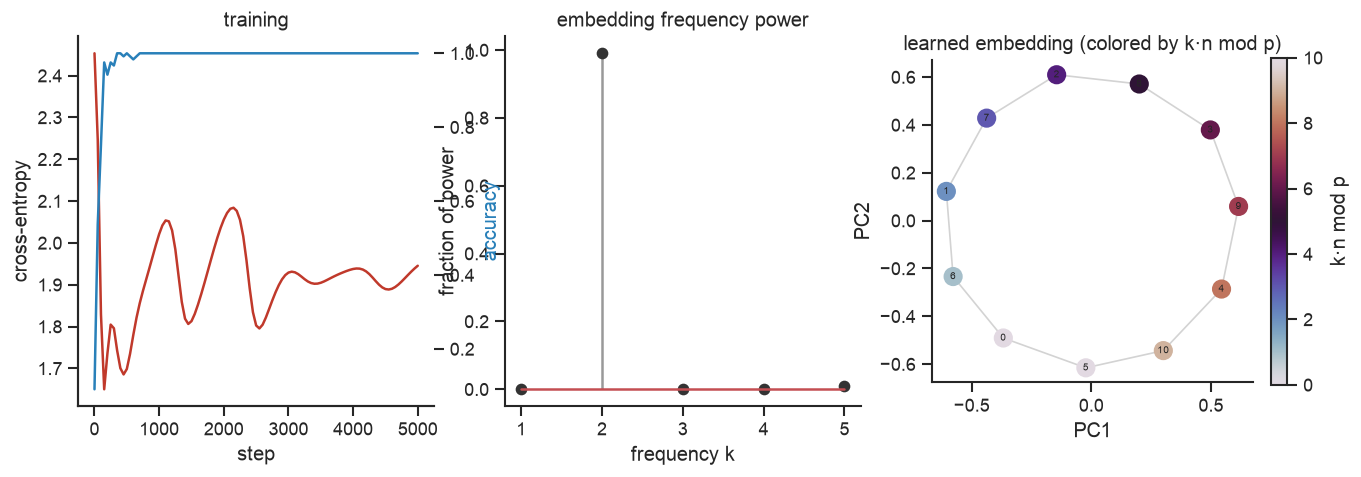

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4))

ax[0].plot(hist[:, 0], hist[:, 1], color="#c0392b", label="loss")
ax[0].set(title="training", xlabel="step", ylabel="cross-entropy")
axt = ax[0].twinx(); axt.plot(hist[:, 0], hist[:, 2], color="#2980b9", label="acc")
axt.set_ylabel("accuracy", color="#2980b9"); axt.spines["top"].set_visible(False)

markerline, stemlines, _ = ax[1].stem(np.arange(1, len(Fpow) + 1), Fpow)
plt.setp(markerline, color="#333"); plt.setp(stemlines, color="#999")
ax[1].set(title="embedding frequency power", xlabel="frequency k", ylabel="fraction of power")

# color by k*n mod p (sweeps smoothly around the ring); connect tokens in angular order
kn = (k * nn) % p                       # angular coordinate of token n on the circle
ring_order = np.argsort(kn)             # walk tokens in angular order -> traces the rim cleanly
scatter2d(ax[2], fig, pcs, kn, cmap="twilight", clabel="k·n mod p", xlabel="PC1", ylabel="PC2",
          title="learned embedding (colored by k·n mod p)", path=ring_order, annotate=True, s=110)
plt.show()

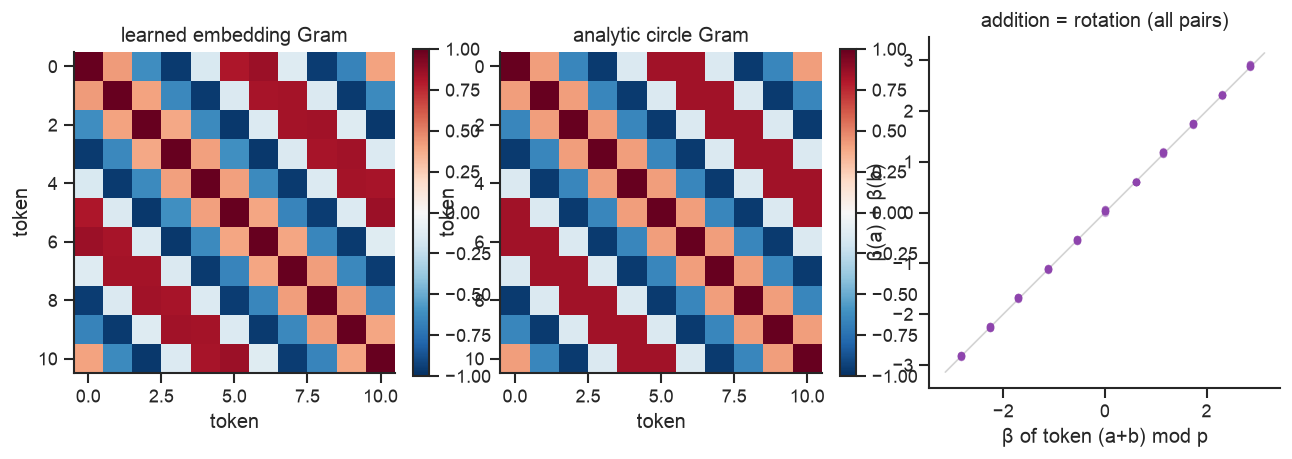

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))

# learned vs analytic geometry, as Gram matrices (similarity = cos of angle gap)
Glearned = np.corrcoef(embc)            # row-correlation Gram of the learned embedding
Ganalytic = circle @ circle.T           # cos(2 pi k (i-j)/p): the analytic circle Gram
for axi, Gm, ttl in [(ax[0], Glearned, "learned embedding Gram"), (ax[1], Ganalytic, "analytic circle Gram")]:
    im = axi.imshow(Gm, cmap="RdBu_r", vmin=-1, vmax=1)
    axi.set(title=ttl, xlabel="token", ylabel="token")
    fig.colorbar(im, ax=axi, fraction=0.046)

# addition = rotation: each token's angle relative to token 0 is additive mod 2*pi
ang = np.arctan2(pcs[:, 1], pcs[:, 0])
beta = np.angle(np.exp(1j * (ang - ang[0])))             # angle rel. to token 0  (= 2*pi*k*n/p)
ai, bi = a.numpy(), b.numpy()
lhs = np.angle(np.exp(1j * (beta[ai] + beta[bi])))       # rotate token a by token b
rhs = beta[(ai + bi) % p]                                # angle of the true sum token
ax[2].plot([-np.pi, np.pi], [-np.pi, np.pi], color="lightgray", lw=1, zorder=0)
ax[2].scatter(rhs, lhs, s=12, alpha=0.4, color="#8e44ad", zorder=2)
ax[2].set(title="addition = rotation (all pairs)", xlabel="β of token (a+b) mod p", ylabel="β(a) + β(b)")
ax[2].set_aspect("equal")
plt.show()

## 5. Interference, superposition, and a universal code

Put several families in one matrix and the decoder becomes the **union** of their sufficient statistics — the factorization $L\approx E\cdot D$ still holds, but $D$ is now a shared dictionary serving every family. Three questions: what does the decomposition look like, what does a capacity bottleneck do, and what happens when we pile in *many* families?

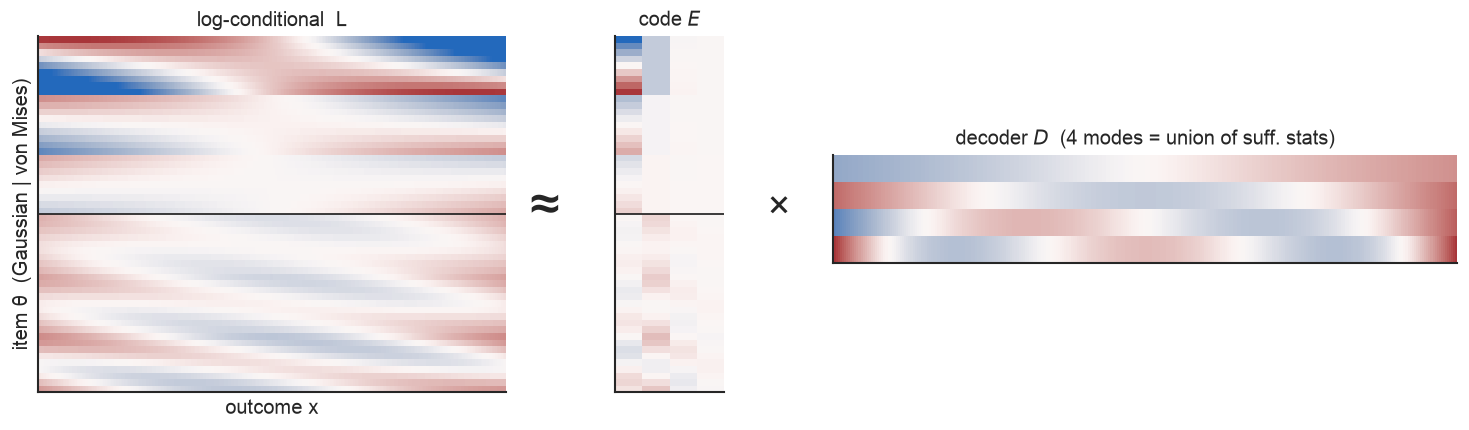

spectrum fraction: [0.567 0.312 0.086 0.035 0.    0.   ]  -> rank 4 = 2 (Gaussian) + 2 (von Mises)


In [15]:
# mix two families over a shared outcome x; the decoder = the UNION of their sufficient statistics
def mixed(shared=True):
    gm = np.linspace(-2, 2, 9); gs = np.linspace(0.5, 1.1, 3); G = np.array([(m, s) for s in gs for m in gm])
    vmm = np.linspace(-np.pi, np.pi, 9, endpoint=False); vk = np.array([1.5, 2.5, 4.0])
    Vp = np.array([(m, k) for k in vk for m in vmm]); Z = np.zeros
    if shared:
        x = np.linspace(-np.pi, np.pi, 300)
        Lg = -0.5 * ((x[None] - G[:, 0:1]) / G[:, 1:2]) ** 2 - np.log(G[:, 1:2]); Lv = Vp[:, 1:2] * np.cos(x[None] - Vp[:, 0:1])
    else:
        xl = np.linspace(-np.pi, np.pi, 150); xr = np.linspace(-np.pi, np.pi, 150); x = np.r_[xl, xr]
        Lg = np.concatenate([-0.5 * ((xl[None] - G[:, 0:1]) / G[:, 1:2]) ** 2 - np.log(G[:, 1:2]), Z((len(G), 150))], 1)
        Lv = np.concatenate([Z((len(Vp), 150)), Vp[:, 1:2] * np.cos(xr[None] - Vp[:, 0:1])], 1)
    return np.vstack([Lg, Lv]), np.array([0] * len(Lg) + [1] * len(Lv)), x, G, Vp

L, fam, xmix, G, Vp = mixed(True); Lc, E, D, S, nu = factor_logcond(L); ng = int((fam == 0).sum())

# decomposition view:  L  ≈  E  ×  D   (rank 4 = {x, x²} ∪ {cos, sin})
fig = plt.figure(figsize=(13, 4.5)); fig.set_constrained_layout(False)
axL = fig.add_axes([0.05, 0.16, 0.30, 0.66]); axE = fig.add_axes([0.42, 0.16, 0.07, 0.66]); axD = fig.add_axes([0.56, 0.40, 0.40, 0.20])
vL = np.percentile(np.abs(Lc), 98); axL.imshow(Lc, aspect="auto", cmap="vlag", vmin=-vL, vmax=vL); axL.axhline(ng - 0.5, color="k", lw=1)
axL.set(title="log-conditional  L", xlabel="outcome x", ylabel="item θ  (Gaussian | von Mises)"); axL.set_xticks([]); axL.set_yticks([])
vE = np.abs(E[:, :4]).max(); axE.imshow(E[:, :4], aspect="auto", cmap="vlag", vmin=-vE, vmax=vE); axE.axhline(ng - 0.5, color="k", lw=1)
axE.set(title="code $E$"); axE.set_xticks([]); axE.set_yticks([])
vD = np.abs(D[:4]).max(); axD.imshow(D[:4], aspect="auto", cmap="vlag", vmin=-vD, vmax=vD)
axD.set(title="decoder $D$  (4 modes = union of suff. stats)"); axD.set_xticks([]); axD.set_yticks([])
fig.text(0.375, 0.5, "≈", fontsize=32, ha="center", va="center"); fig.text(0.525, 0.5, "×", fontsize=24, ha="center", va="center")
plt.show()
print("spectrum fraction:", (S[:6] / S[:6].sum()).round(3), " -> rank 4 = 2 (Gaussian) + 2 (von Mises)")

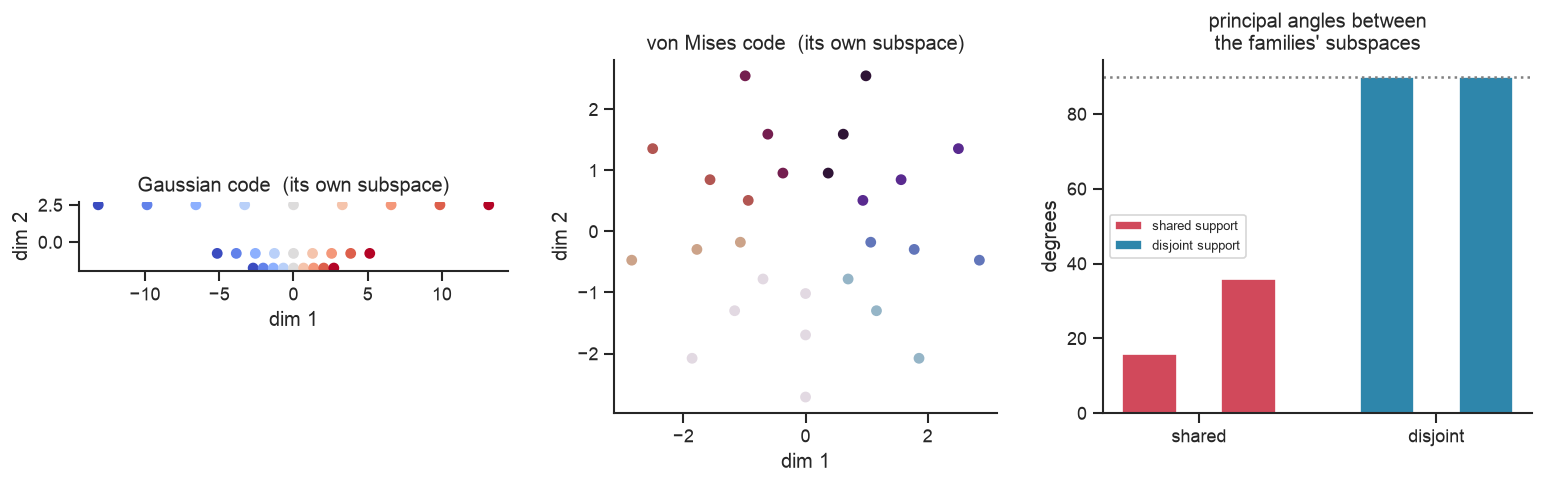

shared-support principal angles between {x,x²} and {cos,sin}: [15.9 35.8]°   (disjoint support -> 90°, 90°)


In [16]:
# each family has its OWN geometry in its OWN subspace — they are not one shared coordinate system
eg = eig_embed(double_center(E[:ng, :4] @ E[:ng, :4].T), 2)[0]      # Gaussian code, its own 2 dims
ev = eig_embed(double_center(E[ng:, :4] @ E[ng:, :4].T), 2)[0]      # von Mises code, its own 2 dims
def _ortho(F): F = F - (F * nu).sum(1, keepdims=True); return np.linalg.qr((F * np.sqrt(nu)).T)[0]
def _angles(F1, F2): return np.degrees(np.arccos(np.clip(np.linalg.svd(_ortho(F1).T @ _ortho(F2), compute_uv=False), -1, 1)))
ash = _angles(np.vstack([xmix, xmix ** 2]), np.vstack([np.cos(xmix), np.sin(xmix)]))   # subspace overlap, shared support

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
ax[0].scatter(eg[:, 0], eg[:, 1], c=G[:, 0], cmap="coolwarm", s=30)
ax[0].set(title="Gaussian code  (its own subspace)", xlabel="dim 1", ylabel="dim 2"); ax[0].set_aspect("equal")
ax[1].scatter(ev[:, 0], ev[:, 1], c=Vp[:, 0], cmap="twilight", s=30)
ax[1].set(title="von Mises code  (its own subspace)", xlabel="dim 1", ylabel="dim 2"); ax[1].set_aspect("equal")
ax[2].bar([0, 1], ash, color="#d1495b", width=0.55, label="shared support")
ax[2].bar([2.4, 3.4], [90, 90], color="#2e86ab", width=0.55, label="disjoint support")
ax[2].axhline(90, color="gray", ls=":")
ax[2].set(title="principal angles between\nthe families' subspaces", ylabel="degrees",
          xticks=[0.5, 2.9], xticklabels=["shared", "disjoint"]); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"shared-support principal angles between {{x,x²}} and {{cos,sin}}: {ash.round(1)}°   (disjoint support -> 90°, 90°)")

/var/folders/10/z4g4n3k17mb0_rvqyc1wx1l40000gn/T/ipykernel_80000/614664260.py:15: UserWarning: Glyph 8834 (\N{SUBSET OF}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
/Users/danielwurgaft/Documents/obsidian-vault/08 Projects/Predicting Representational Geometry/.venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8834 (\N{SUBSET OF}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


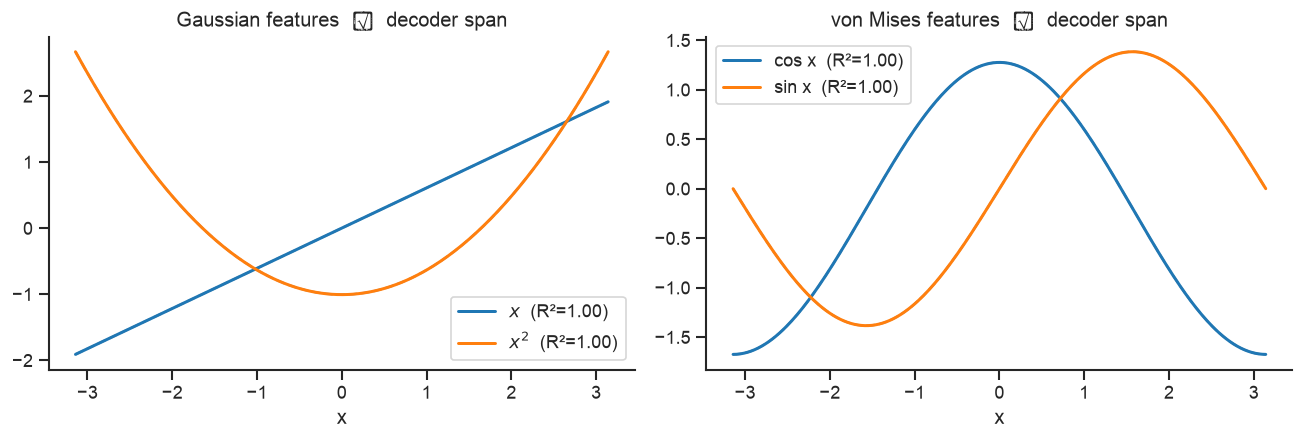

In [17]:
# the decoder span contains each family's analytic sufficient statistic (dashed = analytic, solid = recovered)
def proj(f):
    fc = f - (f * nu).sum(); Dk = D[:4]
    coef = (fc * nu) @ Dk.T @ np.linalg.inv((Dk * nu) @ Dk.T + 1e-9 * np.eye(4)); p = coef @ Dk
    return p, 1 - ((fc - p) ** 2 * nu).sum() / ((fc ** 2 * nu).sum())
un = lambda f: (lambda g: g / np.sqrt((g * g * nu).sum()))(f - (f * nu).sum())
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8)); cols = ["#1f77b4", "#ff7f0e"]
for axi, feats, ttl in [(ax[0], [("$x$", xmix), ("$x^2$", xmix ** 2)], "Gaussian features  ⊂  decoder span"),
                        (ax[1], [("cos x", np.cos(xmix)), ("sin x", np.sin(xmix))], "von Mises features  ⊂  decoder span")]:
    for (nme, f), col in zip(feats, cols):
        p, r2 = proj(f)
        axi.plot(xmix, un(f), "--", color="k", lw=1.4, alpha=0.5)
        axi.plot(xmix, un(p), color=col, lw=1.8, label=f"{nme}  (R²={r2:.2f})")
    axi.set(title=ttl, xlabel="x"); axi.legend()
plt.tight_layout(); plt.show()

**But in which basis are they separate?** The code `E` lives in the **SVD basis** — orthonormal and variance-ordered — and there von Mises *bleeds into the Gaussian's top dimensions*: the SVD sees only second-order structure, so it rotates the correlated sufficient statistics together and orders by variance. The families are block-separated only in the (non-orthogonal) **sufficient-statistic basis**, which the SVD has no reason to find. To recover it **blind** — without knowing `{x, x², cos, sin}` — you need higher-order structure: the basis in which each item's code is **sparse**. That is sparse coding / a sparse autoencoder.

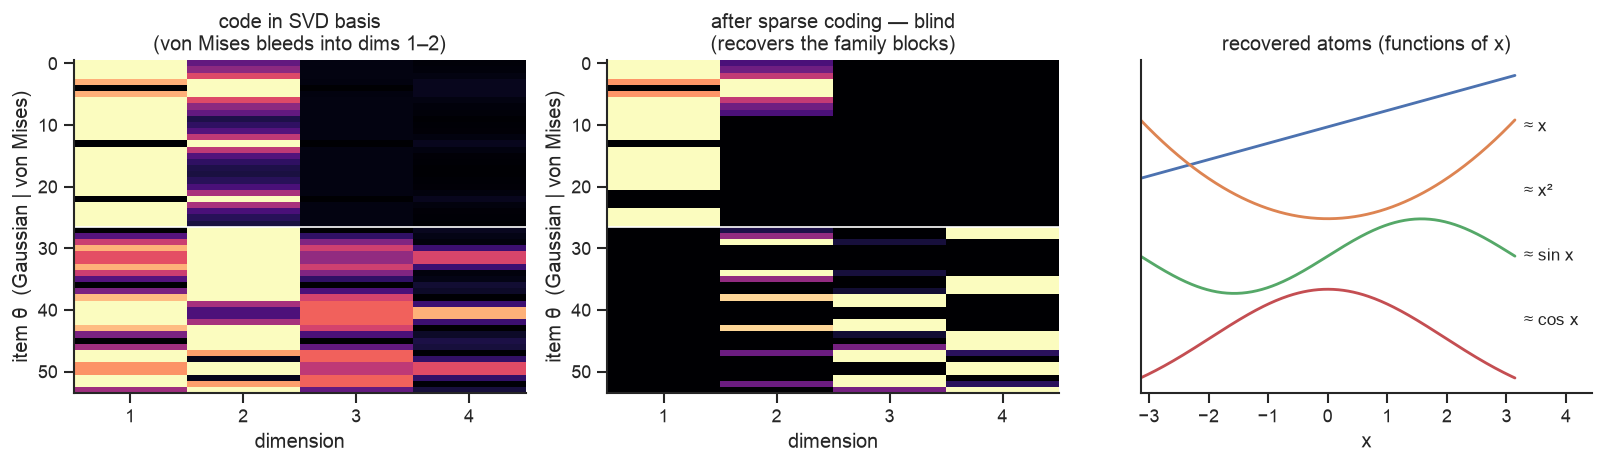

atom usage [Gaussian, von Mises]: [(np.float64(3.03), np.float64(0.0)), (np.float64(0.98), np.float64(0.17)), (np.float64(0.0), np.float64(0.43)), (np.float64(0.0), np.float64(0.64))]


In [18]:
# recover the basis BLIND: sparse coding on the code E (no knowledge of the sufficient statistics)
from sklearn.decomposition import DictionaryLearning
Ec = E[:, :4]
dl = DictionaryLearning(n_components=4, alpha=1.0, random_state=0, max_iter=2000, transform_alpha=1.0)
Csp = dl.fit_transform(Ec)
order = np.argsort(np.abs(Csp[:ng]).mean(0) - np.abs(Csp[ng:]).mean(0))[::-1]   # Gaussian-used atoms first
Csp = Csp[:, order]; atoms = dl.components_[order] @ D[:4]
un = lambda f: (lambda g: g / np.sqrt((g * g * nu).sum()))(f - (f * nu).sum())
truth = {"x": xmix, "x²": xmix ** 2, "cos x": np.cos(xmix), "sin x": np.sin(xmix)}
best = lambda f: max(truth, key=lambda k: abs((un(f) * un(truth[k]) * nu).sum()))

fig, ax = plt.subplots(1, 3, figsize=(13.5, 4))
def hm(a, M, t):
    Mn = np.abs(M); Mn = Mn / (Mn.max(1, keepdims=True) + 1e-9)
    a.imshow(Mn, aspect="auto", cmap="magma"); a.axhline(ng - 0.5, color="w", lw=1)
    a.set(title=t, xlabel="dimension", ylabel="item θ  (Gaussian | von Mises)"); a.set_xticks(range(4)); a.set_xticklabels(range(1, 5))
hm(ax[0], Ec, "code in SVD basis\n(von Mises bleeds into dims 1–2)")
hm(ax[1], Csp, "after sparse coding — blind\n(recovers the family blocks)")
for j in range(4):
    ax[2].plot(xmix, un(atoms[j]) + (3 - j) * 2.4, lw=1.7)
    ax[2].text(xmix[-1] + 0.15, (3 - j) * 2.4, f"≈ {best(atoms[j])}", va="center", fontsize=10)
ax[2].set(title="recovered atoms (functions of x)", xlabel="x", yticks=[]); ax[2].set_xlim(xmix[0], xmix[-1] + 1.3)
plt.tight_layout(); plt.show()
print("atom usage [Gaussian, von Mises]:", [(round(np.abs(Csp[:ng, j]).mean(), 2), round(np.abs(Csp[ng:, j]).mean(), 2)) for j in range(4)])

**Sparse coding finds it.** With no knowledge of the sufficient statistics it recovers the family **blocks** (Gaussian → atoms 1–2, von Mises → atoms 3–4, zero off-block), and the atoms come out *as* the sufficient statistics themselves — $x, x^2, \cos x, \sin x$. SVD/PCA hides the features in superposition because it only sees variance; **sparsity is what disentangles them**. This is the toy version of running a sparse autoencoder on a transformer: the interpretable features aren't the principal components, they're the sparse, non-orthogonal dictionary the codes are sparse in. *(The faint von Mises activation on the Gaussian's $x^2$ atom is a benign **centering offset** — the shared column-mean is Gaussian-heavy, so it shifts the whole von Mises cluster a little; it carries no real $x^2$ structure and vanishes with disjoint support.)*

Each family has its **own** geometry in its **own** subspace — the Gaussian **fan** (the `{x,x²}` directions), the von Mises **annulus** (`{cos,sin}`) — and the decoder reproduces each family's sufficient statistic exactly (R²=1). They are **not one shared coordinate system**: plotting both on the *combined* top-2 PCs would collapse von Mises, because its directions are nearly orthogonal to the Gaussian's. How much they actually **share** directions is set by the outcome support — on **shared** support the subspaces overlap (principal angles ≈ 16°/36°, because the sufficient statistics are correlated there), on **disjoint** support they're orthogonal (90°). That partial overlap is the substrate for what happens under a capacity bottleneck.

**A universal code.** The decoder is the **union of every family's sufficient statistics**. Hold the distributions fixed at **150** and add families one at a time. Shown as the same decomposition $L\approx E\times D$ at growing family counts:
- **Diverse families** (periodic distributions with 1, 2, 3, 4 modes — von Mises at increasing frequency, all on the *same* support) → rank **grows**: their sufficient statistics $\{\cos kx,\sin kx\}$ are mutually orthogonal, so the codes stay separate and the decoder stacks them. A sparse code (**dictionary learning**, below) recovers the family blocks exactly. The orthogonality is non-trivial — the families share the support; it comes from their statistics not overlapping, not from living in different places.
- **Smooth families** → rank **saturates**: their sufficient statistics are all low-order polynomials, so they share one **cumulant (Hermite) tower**.

Rows are sorted within each family and labelled; identical axes are used throughout.

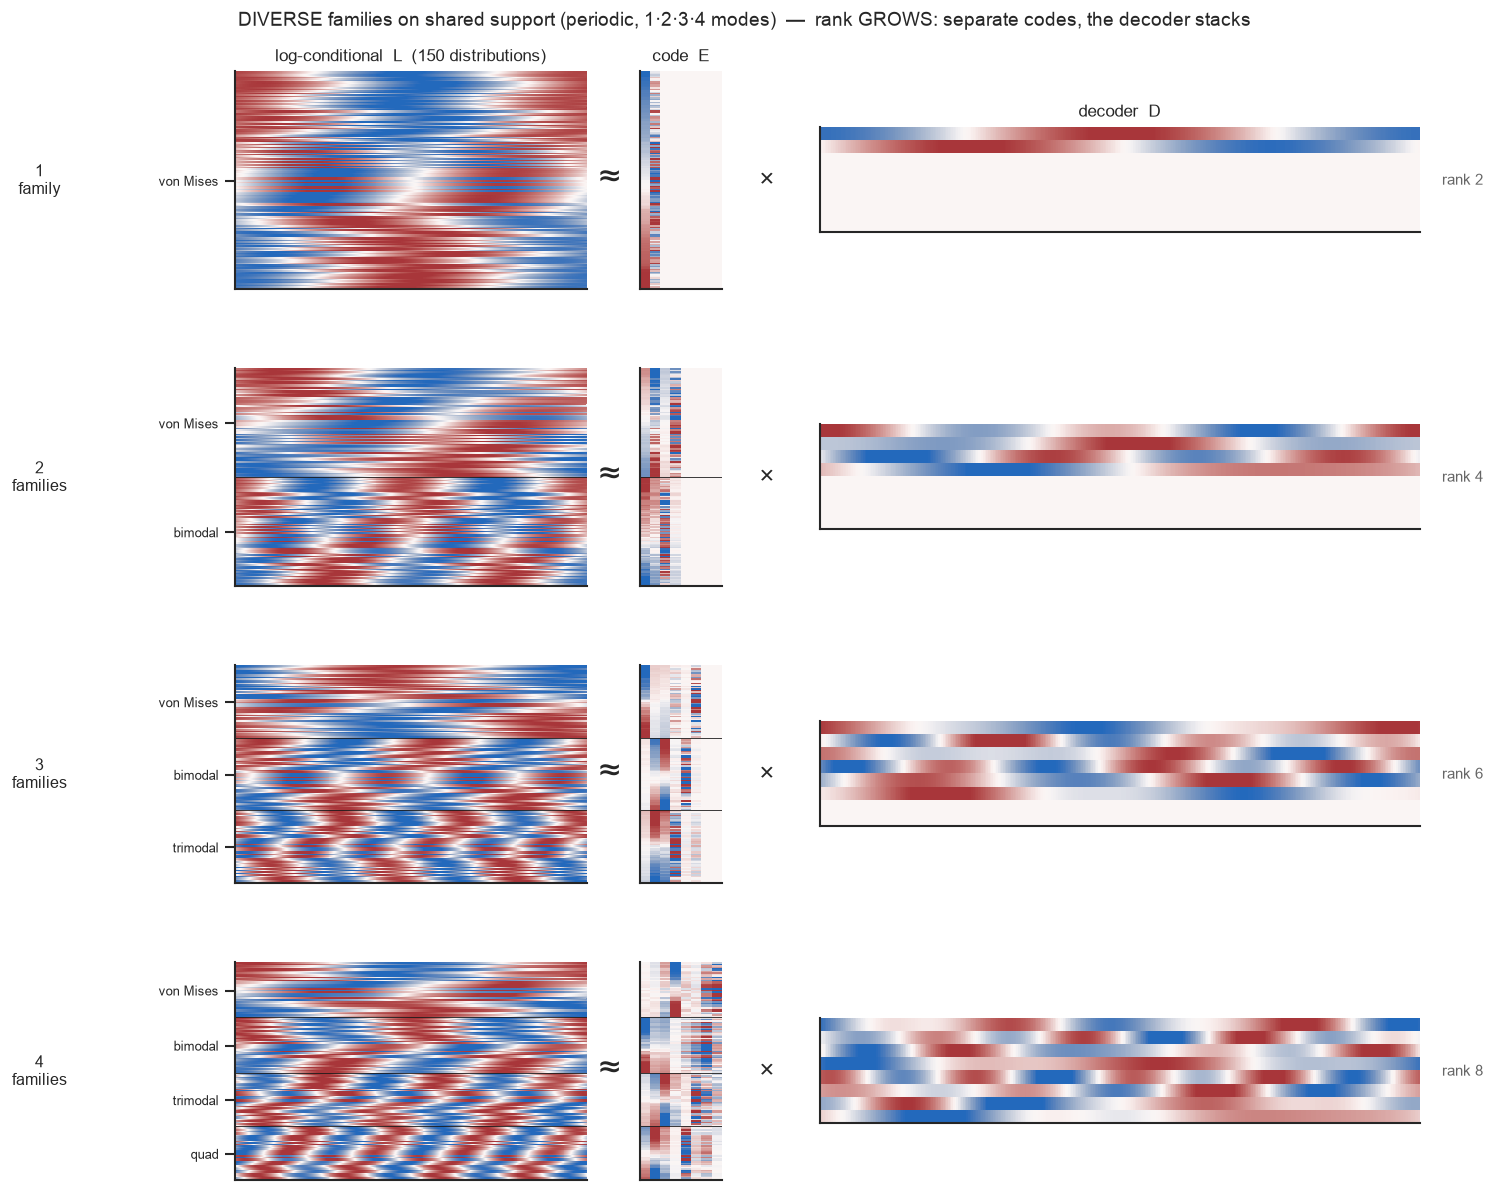

diverse rank vs #families: {1: 2, 2: 4, 3: 6, 4: 8}


In [19]:
# shared helper: the decomposition L ≈ E × D as the number of families grows (150 distributions throughout)
def decomp_staircase(pool, Fs, factor, xgrid, sup):
    KD = 8
    def _pn(M):
        s = np.percentile(np.abs(M), 90, axis=1, keepdims=True) + 1e-9; return np.clip(M / s, -1, 1)
    nm = [n.split(" {")[0] for n, _ in pool]
    fig = plt.figure(figsize=(12.5, 11)); fig.set_constrained_layout(False); ranks = {}
    for r, Fn in enumerate(Fs):
        rg = np.random.default_rng(0); fm = np.array([i % Fn for i in range(150)])
        Lf = np.array([pool[f][1](rg) for f in fm])
        Lc, E, D, Sv = factor(Lf); k = int((Sv > 0.03 * Sv[0]).sum()); ranks[Fn] = k
        parts = []                                                     # sort rows within each family by its own 1st PC
        for f in range(Fn):
            idx = np.where(fm == f)[0]; rows = Lc[idx] - Lc[idx].mean(0)
            key = rows @ np.linalg.svd(rows, full_matrices=False)[2][0]; parts.append(idx[np.argsort(key)])
        order = np.concatenate(parts)
        cnt = [int((fm == f).sum()) for f in range(Fn)]; cen = np.cumsum(cnt) - np.array(cnt) / 2; bnd = np.cumsum(cnt)[:-1]
        yy = 0.74 - r * 0.225
        axL = fig.add_axes([0.16, yy, 0.235, 0.165]); axE = fig.add_axes([0.43, yy, 0.055, 0.165]); axD = fig.add_axes([0.55, yy + 0.043, 0.40, 0.08])
        kk = min(k, KD); E8 = np.zeros((len(Lf), KD)); E8[:, :kk] = E[order, :kk]; D8 = np.zeros((KD, len(xgrid))); D8[:kk] = D[:kk]
        axL.imshow(_pn(Lc[order]), aspect="auto", cmap="vlag", vmin=-1, vmax=1)
        axE.imshow(_pn(E8.T).T, aspect="auto", cmap="vlag", vmin=-1, vmax=1)
        axD.imshow(_pn(D8), aspect="auto", cmap="vlag", vmin=-1, vmax=1)
        for b in bnd:
            axL.axhline(b - 0.5, color="k", lw=0.5); axE.axhline(b - 0.5, color="k", lw=0.5)
        axL.set_xticks([]); axL.set_yticks(cen); axL.set_yticklabels([nm[f] for f in range(Fn)], fontsize=7.5)
        for a in (axE, axD):
            a.set_xticks([]); a.set_yticks([])
        fig.text(0.03, yy + 0.082, f"{Fn}\nfamil{'y' if Fn == 1 else 'ies'}", va="center", ha="center", fontsize=9.5)
        fig.text(0.41, yy + 0.082, "≈", fontsize=22, ha="center", va="center")
        fig.text(0.515, yy + 0.082, "×", fontsize=16, ha="center", va="center")
        fig.text(0.965, yy + 0.082, f"rank {k}", va="center", fontsize=9, color="0.4")
        if r == 0:
            axL.set_title("log-conditional  L  (150 distributions)", fontsize=10); axE.set_title("code  E", fontsize=10); axD.set_title("decoder  D", fontsize=10)
    fig.suptitle(sup, y=0.95, fontsize=11.5)
    plt.show(); return ranks

# DIVERSE families on SHARED support [-π,π]: periodic distributions with 1,2,3,4 modes (von Mises at increasing frequency).
# different frequencies are mutually orthogonal under the shared measure -> perfectly separate codes.
xp = np.linspace(-np.pi, np.pi, 360, endpoint=False)
vmk = lambda k: (lambda rg: rg.uniform(1.5, 3.2) * np.cos(k * (xp - rg.uniform(-np.pi, np.pi))))
fams_div = [
    ("von Mises {cos,sin}",  vmk(1)),
    ("bimodal {cos2,sin2}",  vmk(2)),
    ("trimodal {cos3,sin3}", vmk(3)),
    ("quad {cos4,sin4}",     vmk(4)),
]
def make_div(Fn, n=150):
    rg = np.random.default_rng(0); fm = np.array([i % Fn for i in range(n)])
    return np.array([fams_div[f][1](rg) for f in fm]), fm
rdiv = decomp_staircase(fams_div, [1, 2, 3, 4], lambda Lf: factor_logcond(Lf)[:4], xp,
                        "DIVERSE families on shared support (periodic, 1·2·3·4 modes)  —  rank GROWS: separate codes, the decoder stacks")
print("diverse rank vs #families:", rdiv)

**Recovering the separate blocks.** In the raw SVD basis the families look mixed (it is variance-ordered, so it rotates the codes together). But their sufficient statistics are *mutually orthogonal* — different Fourier frequencies on the same support — so a sparse code disentangles them: **dictionary learning** recovers the family **blocks**, each family activating exactly its own pair of atoms, and the atoms come out *as* the sufficient statistics $\{\cos kx,\sin kx\}$.

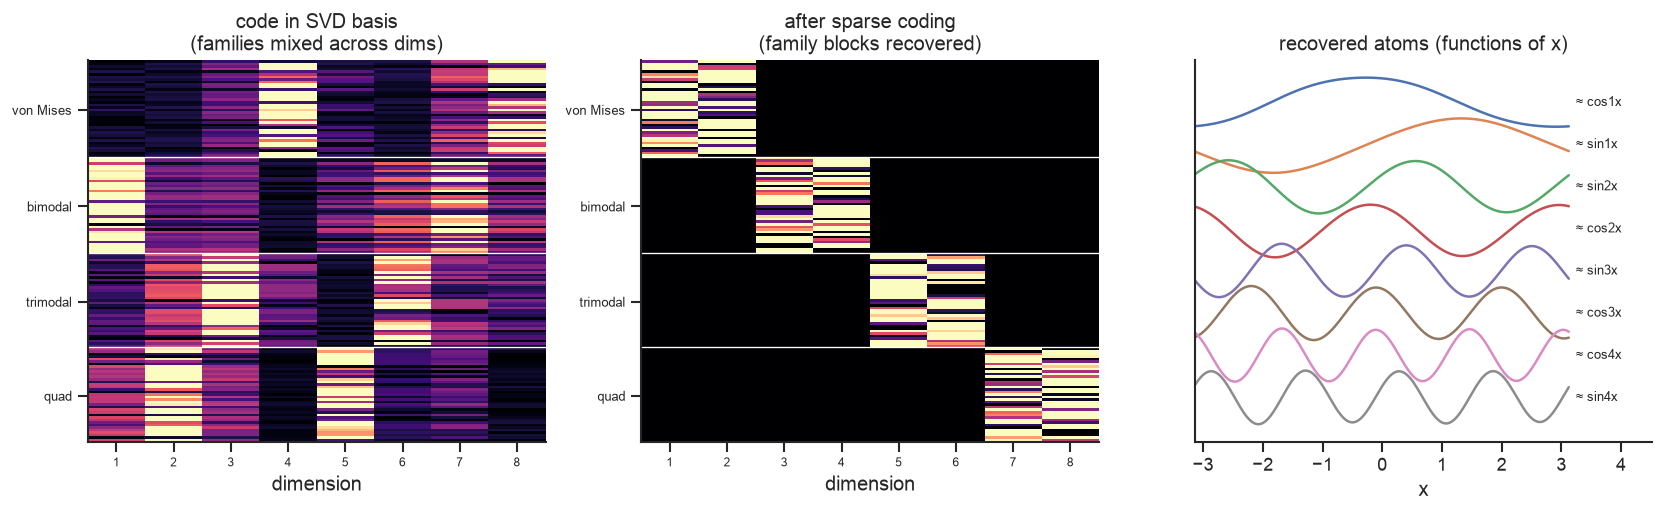

atoms recovered: ['cos1x', 'sin1x', 'sin2x', 'cos2x', 'sin3x', 'cos3x', 'cos4x', 'sin4x']


In [20]:
# dictionary learning on the diverse code -> recover the family blocks (genuinely SEPARATE, on shared support)
from sklearn.decomposition import DictionaryLearning
nD = len(fams_div); Ld, fmd = make_div(nD); Lc, E, D, Sv, nu = factor_logcond(Ld); k = int((Sv > 0.03 * Sv[0]).sum())
Uw = E[:, :k] / Sv[:k]                                              # whiten: comparable-scale code columns
dl = DictionaryLearning(n_components=k, alpha=0.3, random_state=0, max_iter=4000)
C = dl.fit_transform(Uw); atoms = dl.components_ @ D[:k]
fuse = np.array([[np.abs(C[fmd == f, j]).mean() for f in range(nD)] for j in range(k)])
aord = sorted(range(k), key=lambda j: (int(np.argmax(fuse[j])), -fuse[j].max()))   # group atoms by the family that uses them
C = C[:, aord]; atoms = atoms[aord]
iord = np.concatenate([np.where(fmd == f)[0] for f in range(nD)])
cnt = [int((fmd == f).sum()) for f in range(nD)]; cen = np.cumsum(cnt) - np.array(cnt) / 2; bnd = np.cumsum(cnt)[:-1]
nmd = [n.split(" {")[0] for n, _ in fams_div]
un = lambda f: (lambda g: g / np.sqrt((g * g * nu).sum() + 1e-12))(f - (f * nu).sum())
cands = {f"cos{j}x": np.cos(j * xp) for j in range(1, 5)}; cands.update({f"sin{j}x": np.sin(j * xp) for j in range(1, 5)})

fig, ax = plt.subplots(1, 3, figsize=(14, 4.4))
def hm(a, M, t):
    Mn = np.abs(M[iord]); Mn = Mn / (Mn.max(1, keepdims=True) + 1e-9)
    a.imshow(Mn, aspect="auto", cmap="magma")
    for b in bnd:
        a.axhline(b - 0.5, color="w", lw=0.8)
    a.set(title=t, xlabel="dimension"); a.set_xticks(range(M.shape[1])); a.set_xticklabels(range(1, M.shape[1] + 1), fontsize=7)
    a.set_yticks(cen); a.set_yticklabels(nmd, fontsize=8)
hm(ax[0], E[:, :k], "code in SVD basis\n(families mixed across dims)")
hm(ax[1], C, "after sparse coding\n(family blocks recovered)")
for j in range(k):
    a2 = un(atoms[j]); best = max(cands, key=lambda c: abs((a2 * un(cands[c]) * nu).sum()))
    s = np.sign((a2 * un(cands[best]) * nu).sum()) or 1
    ax[2].plot(xp, un(atoms[j]) * s + (k - j) * 2.3, lw=1.5, color="C%d" % (j % 10))
    ax[2].text(xp[-1] + 0.12, (k - j) * 2.3, f"≈ {best}", va="center", fontsize=8)
ax[2].set(title="recovered atoms (functions of x)", xlabel="x", yticks=[]); ax[2].set_xlim(xp[0], xp[-1] + 1.4)
plt.tight_layout(); plt.show()
print("atoms recovered:", [max(cands, key=lambda c: abs((un(atoms[j]) * un(cands[c]) * nu).sum())) for j in range(k)])

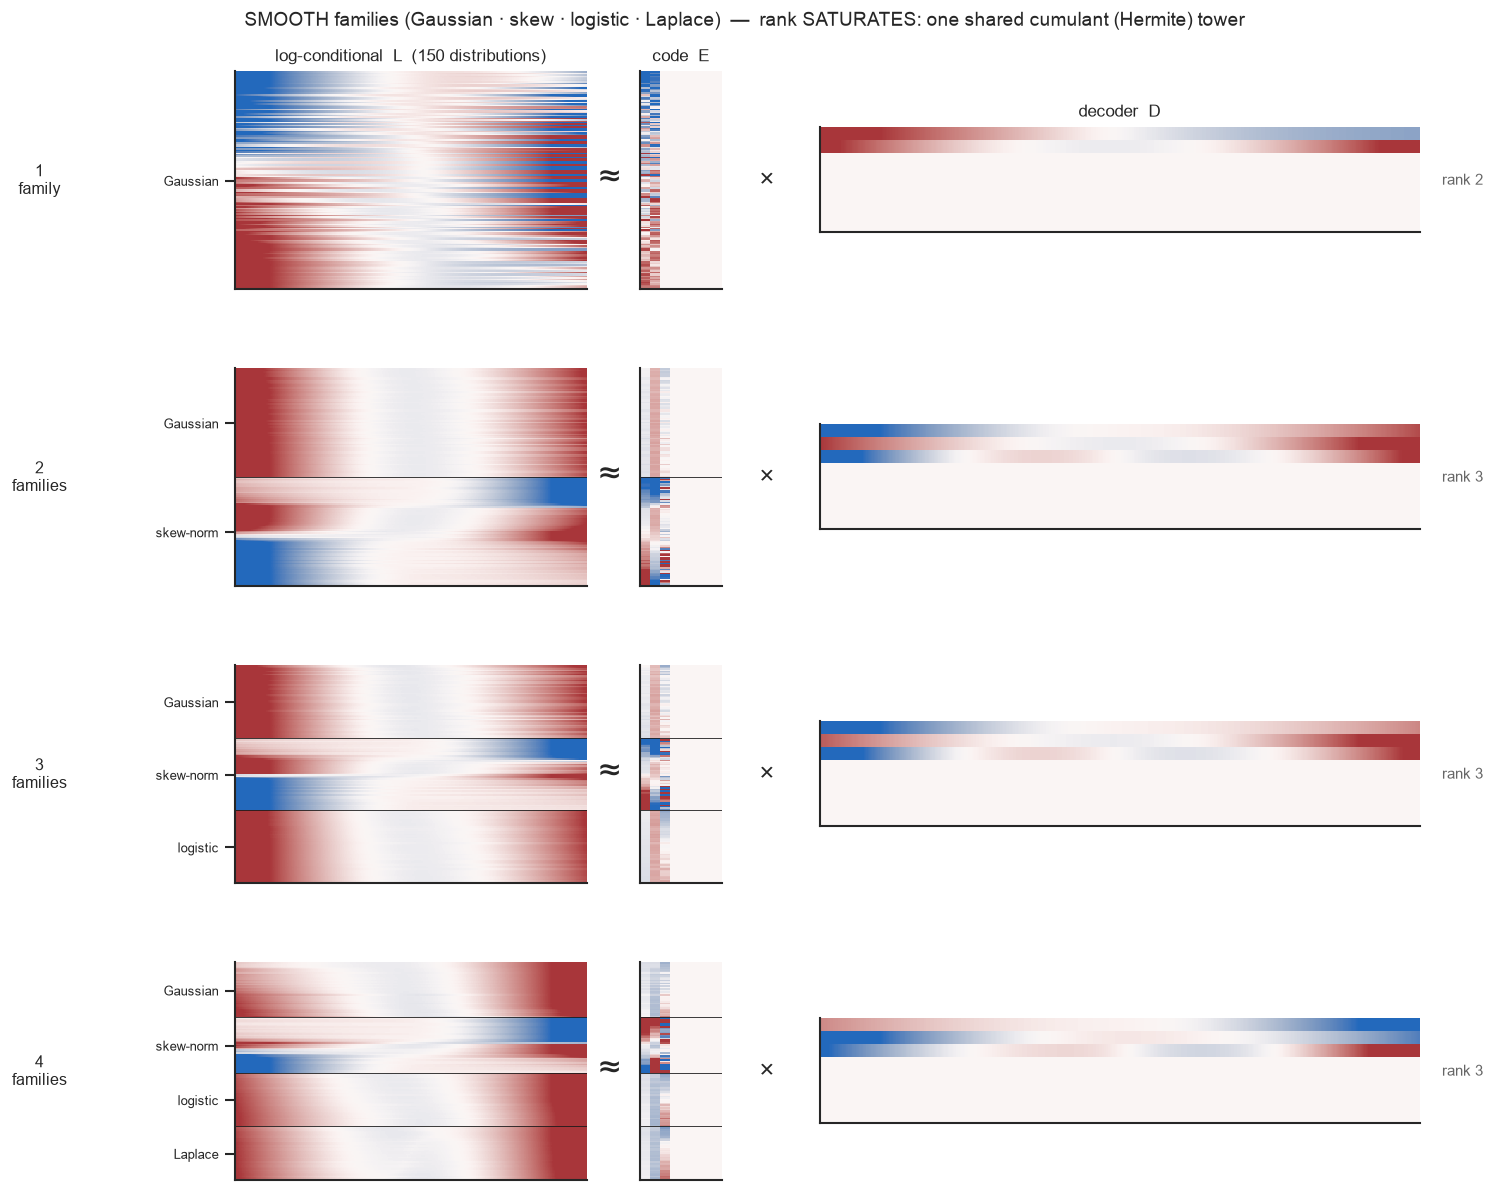

smooth rank vs #families: {1: 2, 2: 3, 3: 3, 4: 3}  — adding smooth families adds no new code


In [21]:
# SMOOTH families: the SAME progression -> rank SATURATES, they share one cumulant (Hermite) tower
from scipy import stats
xu = np.linspace(-5, 5, 500); tau = 1.4; wg = np.exp(-xu ** 2 / (2 * tau ** 2)); wg /= wg.sum()   # Gaussian reference measure
fam_gen = [
    ("Gaussian",  lambda rg: stats.norm.logpdf(xu, rg.uniform(-.8, .8), rg.uniform(.8, 1.3))),
    ("skew-norm", lambda rg: stats.skewnorm.logpdf(xu, rg.uniform(-6, 6), rg.uniform(-.4, .4), rg.uniform(.9, 1.2))),
    ("logistic",  lambda rg: stats.logistic.logpdf(xu, rg.uniform(-.8, .8), rg.uniform(.5, .8))),
    ("Laplace",   lambda rg: stats.laplace.logpdf(xu, rg.uniform(-.8, .8), rg.uniform(.6, 1.0))),
]
names = [n for n, _ in fam_gen]; F = len(fam_gen)
rg = np.random.default_rng(0); fam = np.array([i % F for i in range(150)])
L = np.array([fam_gen[f][1](rg) for f in fam])

def factor_ref(Llog, nu):                                            # factorization under a fixed column measure nu
    N, M = Llog.shape; w = np.full(N, 1.0 / N)
    Lc = Llog - (w @ Llog)[None, :]; Lc = Lc - (Lc @ nu)[:, None]
    U, Sv, Vt = np.linalg.svd(np.sqrt(w)[:, None] * Lc * np.sqrt(nu)[None, :], full_matrices=False)
    return Lc, (U / np.sqrt(w)[:, None]) * Sv, Vt / np.sqrt(nu)[None, :], Sv
He = lambda d: HermiteE(np.eye(d + 1)[d])(xu / tau)
un = lambda f: (lambda g: g / np.sqrt((g * g * wg).sum() + 1e-12))(f - (f * wg).sum())

rsmo = decomp_staircase(fam_gen, [1, 2, 3, 4], lambda Lf: factor_ref(Lf, wg), xu,
                        "SMOOTH families (Gaussian · skew · logistic · Laplace)  —  rank SATURATES: one shared cumulant (Hermite) tower")
print("smooth rank vs #families:", rsmo, " — adding smooth families adds no new code")

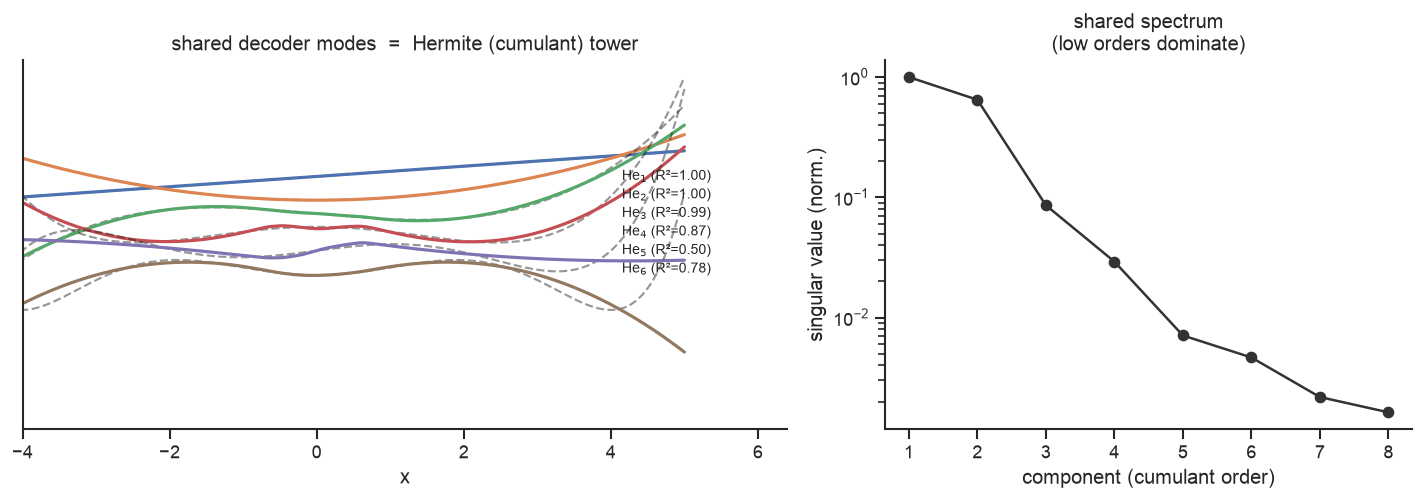

dashed = analytic Hermite, solid = recovered from the joint decoder


In [22]:
# the shared code is the cumulant tower: the joint decoder's top modes = Hermite, low orders first
Lc, E, D, S = factor_ref(L, wg)
K = 6; Dk = D[:K]; Gi = np.linalg.inv((Dk * wg) @ Dk.T + 1e-9 * np.eye(K))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={"width_ratios": [1.45, 1]})
for d in range(1, K + 1):
    fc = un(He(d)); Pp = (fc * wg) @ Dk.T @ Gi @ Dk; r2 = max(0.0, 1 - ((fc - Pp) ** 2 * wg).sum())
    s = np.sign((fc * Pp * wg).sum()) or 1; off = (K - d) * 2.6
    ax[0].plot(xu, fc * s + off, "k--", lw=1.3, alpha=0.45)
    ax[0].plot(xu, Pp * s + off, color="C%d" % (d - 1), lw=1.9)
    ax[0].text(4.15, off, f"He$_{d}$ (R²={r2:.2f})", fontsize=8.5, va="center")
ax[0].set(title="shared decoder modes  =  Hermite (cumulant) tower", xlabel="x", yticks=[]); ax[0].set_xlim(-4, 6.4)
ax[1].semilogy(range(1, 9), S[:8] / S[0], "o-", color="#333")
ax[1].set(title="shared spectrum\n(low orders dominate)", xlabel="component (cumulant order)", ylabel="singular value (norm.)")
plt.tight_layout(); plt.show()
print("dashed = analytic Hermite, solid = recovered from the joint decoder")

So the **universal code is the union of sufficient statistics**, and whether it **stacks or shares** depends on the families. Families with *orthogonal* sufficient statistics — here periodic distributions at distinct frequencies, all on the **same support** — **stack**: each keeps its own block, the rank climbs, and a sparse code recovers them exactly. Smooth, light-tailed families instead **share**: their sufficient statistics are all low-order polynomials, so the union is the compact **cumulant/Hermite tower** (mean, variance, skew, …) with a fast-decaying spectrum (above). Either way the decoder is one shared dictionary — the toy analogue of an LLM reusing a common set of feature directions across many tasks (**superposition**).

## A null case — no shared structure (flat Dirichlet)

What if the items have *no* shared structure to learn? Draw each categorical distribution independently from a **flat Dirichlet** $\mathrm{Dir}(1,\dots,1)$ — the symmetric, maximum-entropy prior over the simplex. A categorical's sufficient statistic is just the one-hot indicator, and $\mathrm{Dir}(1)$ has no preferred direction, so there is nothing to compress. As more distributions are drawn the code should converge to the Dirichlet's *signature*: a **flat spectrum** (all $K-1$ modes equal), a **uniform marginal**, and an **isotropic code** filling the simplex — the exact opposite of the low-rank structured families.

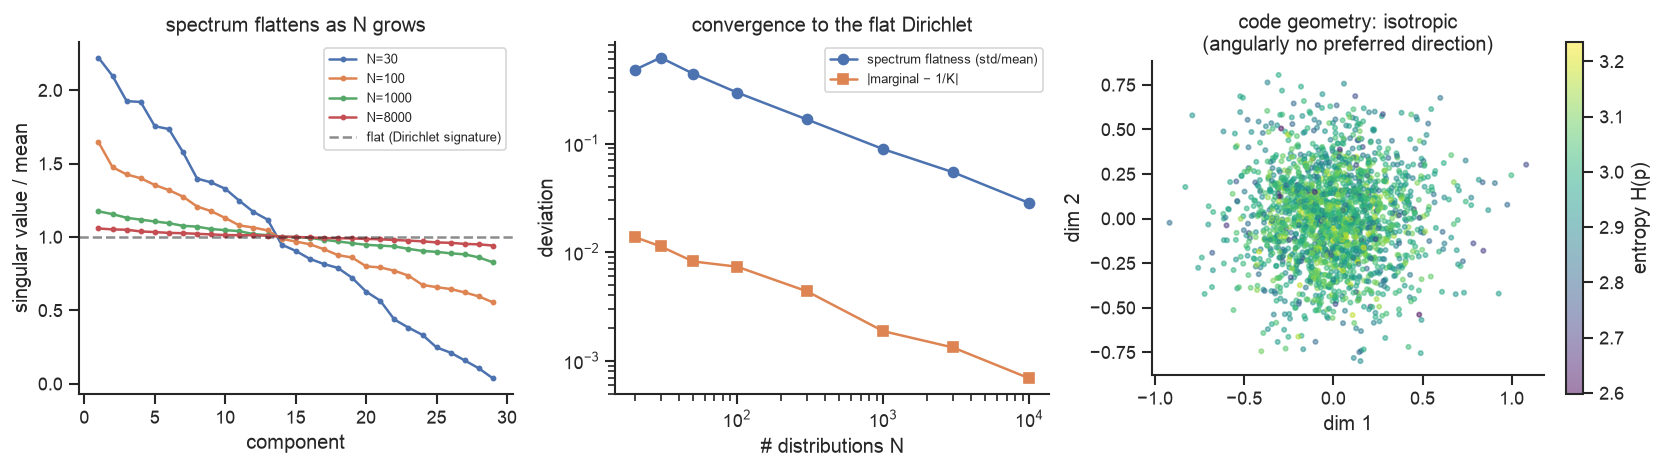

K=30: spectrum flatness std/mean  0.62 (N=30) -> 0.028 (N=1e4);  marginal -> uniform.  Flat Dirichlet = full-rank, isotropic: nothing to compress.


In [23]:
# draw categorical distributions from a flat Dirichlet -> converges to a flat spectrum / isotropic code
K = 30
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for N in [30, 100, 1000, 8000]:
    P = np.random.default_rng(0).dirichlet(np.ones(K), size=N)
    _, _, _, Sv, nu = factor_logcond(np.log(P)); s = Sv[Sv > 1e-9 * Sv[0]]; s = s / s.mean()
    ax[0].plot(range(1, len(s) + 1), s, "o-", ms=2.5, label=f"N={N}")
ax[0].axhline(1, ls="--", color="k", alpha=.5, label="flat (Dirichlet signature)")
ax[0].set(title="spectrum flattens as N grows", xlabel="component", ylabel="singular value / mean"); ax[0].legend(fontsize=8)

Ng = [20, 30, 50, 100, 300, 1000, 3000, 10000]; fl = []; mg = []
for N in Ng:
    P = np.random.default_rng(1).dirichlet(np.ones(K), size=N)
    _, _, _, Sv, nu = factor_logcond(np.log(P)); s = Sv[Sv > 1e-9 * Sv[0]]
    fl.append((s / s.mean()).std()); mg.append(np.abs(nu - 1 / K).max())
ax[1].loglog(Ng, fl, "o-", label="spectrum flatness (std/mean)")
ax[1].loglog(Ng, mg, "s-", label="|marginal − 1/K|")
ax[1].set(title="convergence to the flat Dirichlet", xlabel="# distributions N", ylabel="deviation"); ax[1].legend(fontsize=8)

P = np.random.default_rng(2).dirichlet(np.ones(K), size=2000); _, E, _, _, _ = factor_logcond(np.log(P))
H = -(P * np.log(P + 1e-12)).sum(1)                                    # entropy of each categorical
sc = ax[2].scatter(E[:, 0], E[:, 1], s=7, alpha=.5, c=H, cmap="viridis")
ax[2].set(title="code geometry: isotropic\n(angularly no preferred direction)", xlabel="dim 1", ylabel="dim 2"); ax[2].set_aspect("equal")
fig.colorbar(sc, ax=ax[2], fraction=0.046, label="entropy H(p)")
plt.tight_layout(); plt.show()
print(f"K={K}: spectrum flatness std/mean  {fl[1]:.2f} (N=30) -> {fl[-1]:.3f} (N=1e4);  marginal -> uniform.  "
      f"Flat Dirichlet = full-rank, isotropic: nothing to compress.")

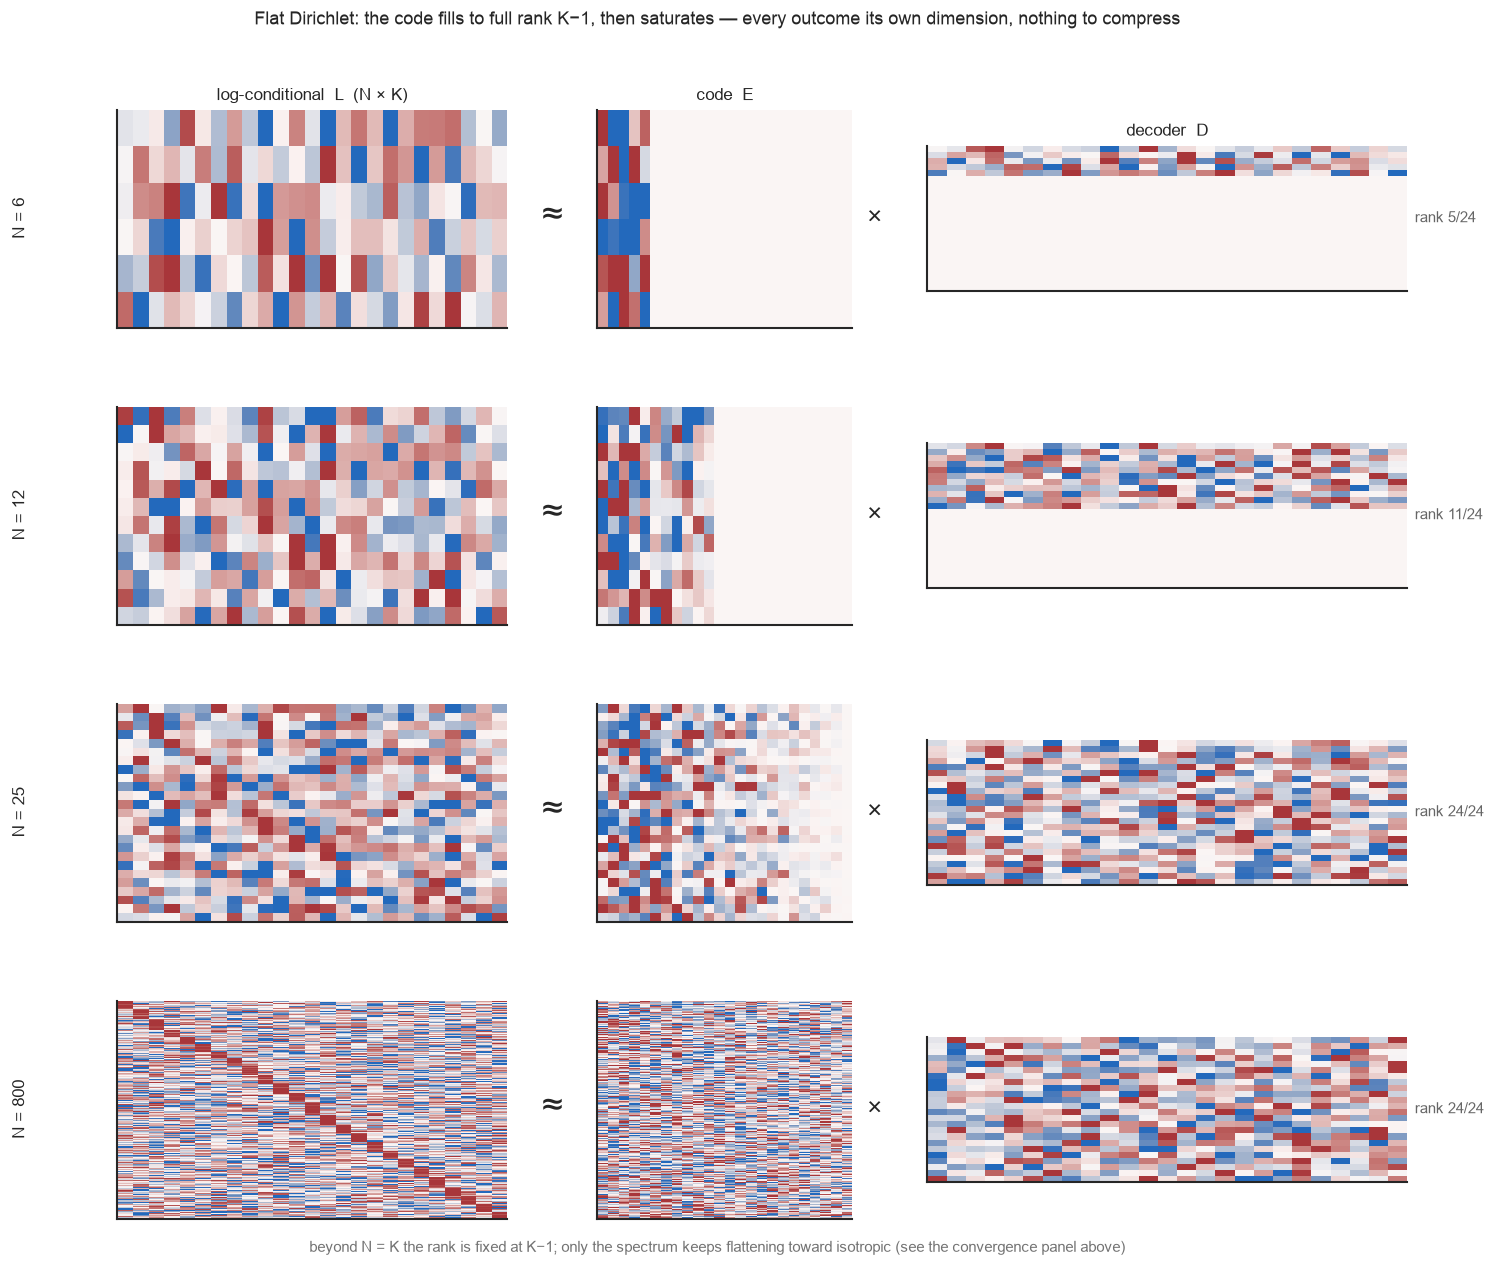

rank vs N: {6: 5, 12: 11, 25: 24, 800: 24}   (cap K−1 = 24)


In [24]:
# the decomposition as N grows: the code fills to full rank K−1 and SATURATES there — the flat Dirichlet never compresses
K = 25; Ns = [6, 12, 25, 800]; KD = K - 1
def _pn(M):
    s = np.percentile(np.abs(M), 90, axis=1, keepdims=True) + 1e-9; return np.clip(M / s, -1, 1)
fig = plt.figure(figsize=(12.5, 11)); fig.set_constrained_layout(False)
for r, N in enumerate(Ns):
    P = np.random.default_rng(0).dirichlet(np.ones(K), size=N)
    Lc, E, D, Sv, nu = factor_logcond(np.log(P)); k = int((Sv > 1e-9 * Sv[0]).sum())
    order = np.argsort(P.argmax(1))
    yy = 0.72 - r * 0.225
    axL = fig.add_axes([0.10, yy, 0.26, 0.165]); axE = fig.add_axes([0.42, yy, 0.17, 0.165]); axD = fig.add_axes([0.64, yy + 0.028, 0.32, 0.11])
    Ek = np.zeros((N, KD)); Ek[:, :k] = E[order, :k]; Dk = np.zeros((KD, K)); Dk[:k] = D[:k]
    axL.imshow(_pn(Lc[order]), aspect="auto", cmap="vlag", vmin=-1, vmax=1)
    axE.imshow(_pn(Ek), aspect="auto", cmap="vlag", vmin=-1, vmax=1)
    axD.imshow(_pn(Dk), aspect="auto", cmap="vlag", vmin=-1, vmax=1)
    for a in (axL, axE, axD):
        a.set_xticks([]); a.set_yticks([])
    fig.text(0.035, yy + 0.083, f"N = {N}", va="center", ha="center", fontsize=10, rotation=90)
    fig.text(0.39, yy + 0.083, "≈", fontsize=22, ha="center", va="center")
    fig.text(0.605, yy + 0.083, "×", fontsize=16, ha="center", va="center")
    fig.text(0.965, yy + 0.083, f"rank {k}/{KD}", va="center", fontsize=9, color="0.4")
    if r == 0:
        axL.set_title("log-conditional  L  (N × K)", fontsize=10); axE.set_title("code  E", fontsize=10); axD.set_title("decoder  D", fontsize=10)
fig.suptitle("Flat Dirichlet: the code fills to full rank K−1, then saturates — every outcome its own dimension, nothing to compress", y=0.96, fontsize=11)
fig.text(0.5, 0.02, "beyond N = K the rank is fixed at K−1; only the spectrum keeps flattening toward isotropic (see the convergence panel above)", ha="center", fontsize=9, color="0.45")
plt.show()
print("rank vs N:", {N: int((factor_logcond(np.log(np.random.default_rng(0).dirichlet(np.ones(K), size=N)))[3] > 1e-9).sum()) for N in Ns}, f"  (cap K−1 = {KD})")

**The identity is recoverable — but only at higher order.** Because the spectrum is flat, SVD leaves the decoder's rotation *undetermined*: it returns an arbitrary orthonormal basis of the simplex, never specifically the indicators — and more data only makes the spectrum flatter, cementing the ambiguity. But the centered log-probs $\log g_x - \overline{\log g}$ (with $g_x\sim\mathrm{Exp}(1)$) are **independent and non-Gaussian** across outcomes, so **ICA** breaks the rotational symmetry SVD is blind to and recovers the canonical **indicator (identity)** basis. Same moral as sparse coding for the structured families: 2nd-order factorization finds the right *subspace*, a higher-order criterion finds the right *basis*.

/Users/danielwurgaft/Documents/obsidian-vault/08 Projects/Predicting Representational Geometry/.venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8811 (\N{MUCH GREATER-THAN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


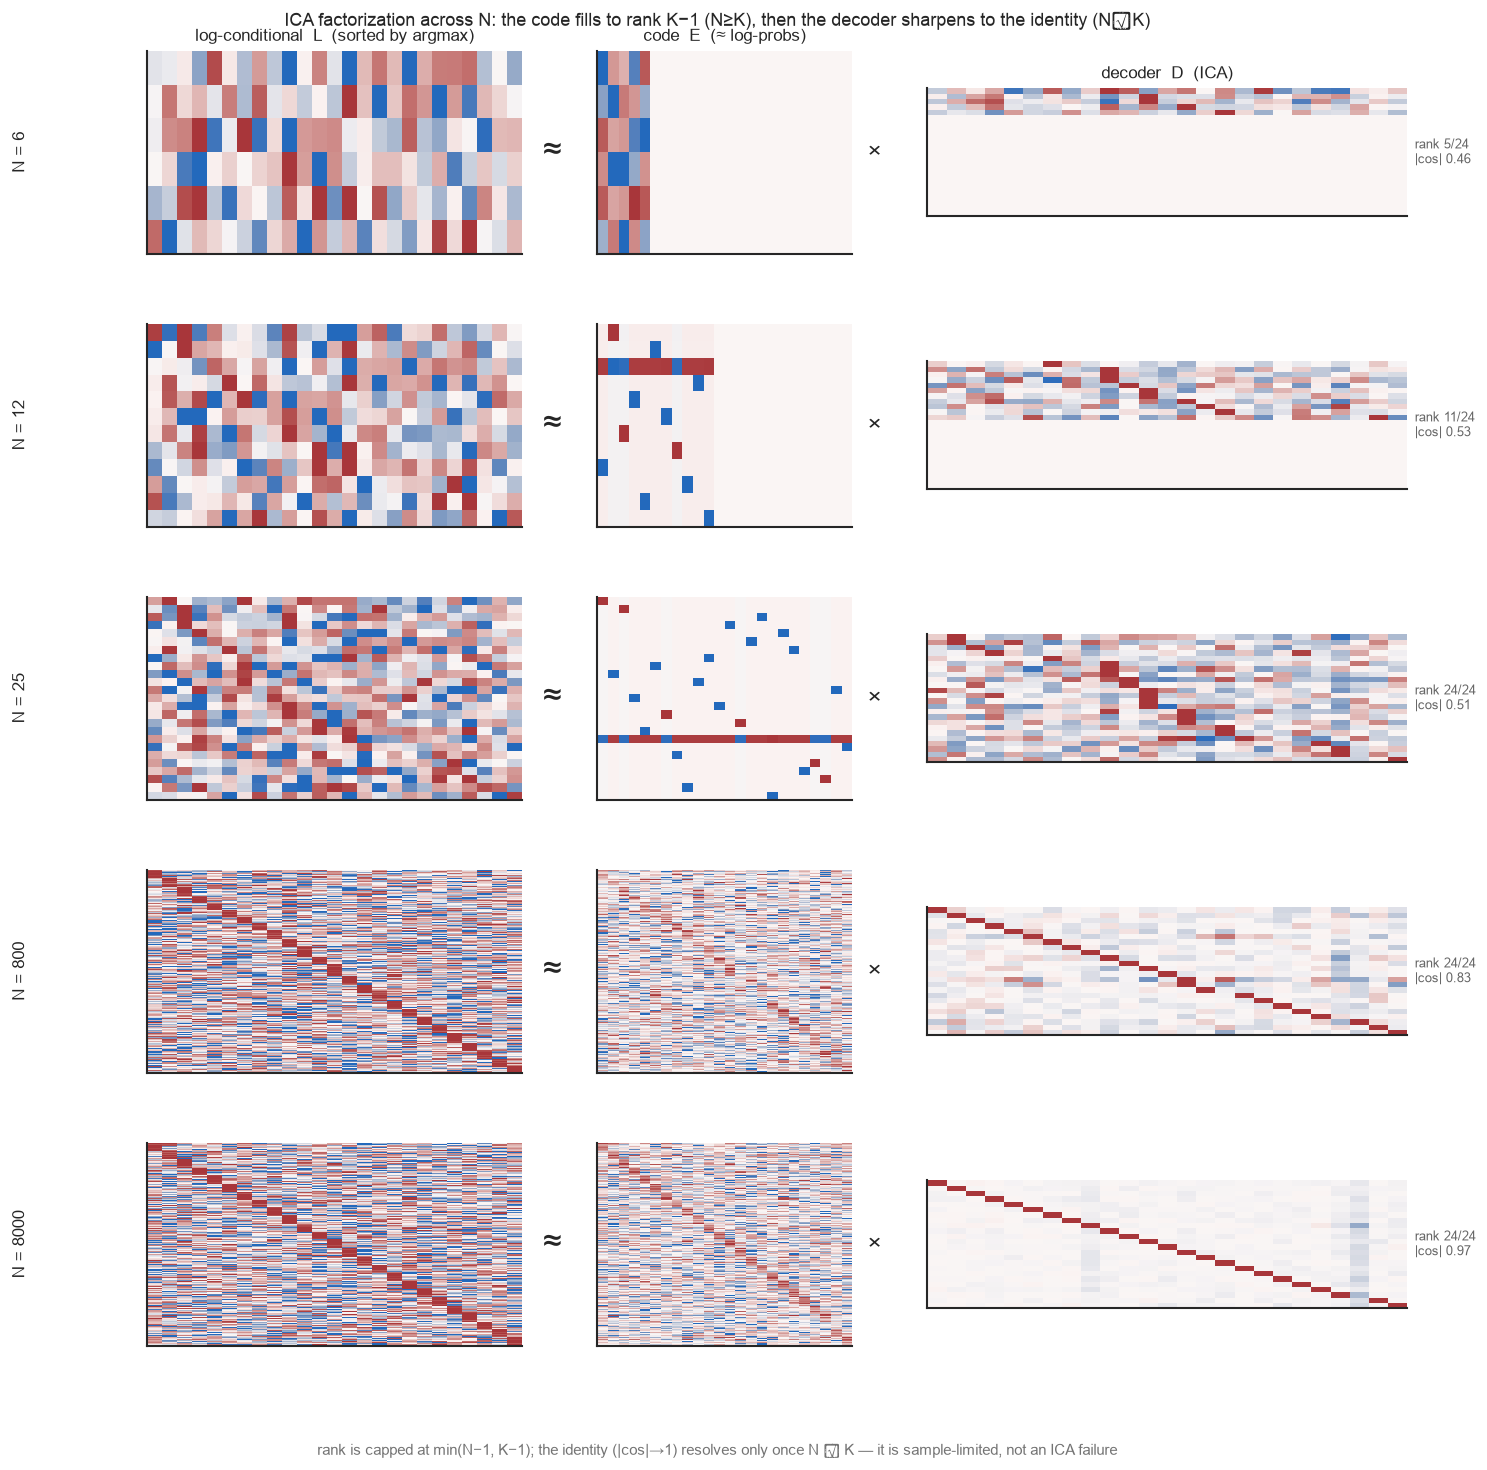

N: (rank, identity |cos|) = {6: None, 12: None, 25: None, 800: None, 8000: None}


In [25]:
# ICA factorization across N (including ranks below K−1): the code fills, then the identity decoder sharpens
import warnings; warnings.filterwarnings("ignore", message="FastICA did not converge")
from sklearn.decomposition import FastICA
K = 25; Ns = [6, 12, 25, 800, 8000]; KD = K - 1
cen = np.eye(K) - 1 / K
cosfn = lambda A: float(np.mean([np.max(np.abs(cen @ (a / np.linalg.norm(a))) / np.linalg.norm(cen, axis=1)) for a in A]))
def _pn(M):
    s = np.percentile(np.abs(M), 90, axis=1, keepdims=True) + 1e-9; return np.clip(M / s, -1, 1)
def _pnmax(M):
    return np.clip(M / (np.abs(M).max(1, keepdims=True) + 1e-9), -1, 1)
fig = plt.figure(figsize=(12.5, 13)); fig.set_constrained_layout(False)
for r, N in enumerate(Ns):
    P = np.random.default_rng(0).dirichlet(np.ones(K), size=N); Lc, E, D, Sv, nu = factor_logcond(np.log(P)); k = int((Sv > 1e-9 * Sv[0]).sum())
    ica = FastICA(n_components=k, whiten="unit-variance", max_iter=4000, tol=1e-4, random_state=0).fit(Lc)
    Sic = ica.transform(Lc); Dic = ica.mixing_.T
    sgn = np.sign(Dic[np.arange(k), np.abs(Dic).argmax(1)]); Dic = Dic * sgn[:, None]; Sic = Sic * sgn[None, :]
    ao = np.argsort(np.abs(Dic).argmax(1)); Dic = Dic[ao]; Sic = Sic[:, ao]; cs = cosfn(ica.mixing_.T)
    ro = np.argsort(P.argmax(1))
    yy = 0.81 - r * 0.175
    axL = fig.add_axes([0.12, yy, 0.25, 0.13]); axE = fig.add_axes([0.42, yy, 0.17, 0.13]); axD = fig.add_axes([0.64, yy + 0.024, 0.32, 0.082])
    Ek = np.zeros((N, KD)); Ek[:, :k] = Sic[ro, :k]; Dk = np.zeros((KD, K)); Dk[:k] = Dic[:k]
    axL.imshow(_pn(Lc[ro]), aspect="auto", cmap="vlag", vmin=-1, vmax=1)
    axE.imshow(_pnmax(Ek), aspect="auto", cmap="vlag", vmin=-1, vmax=1)
    axD.imshow(_pnmax(Dk), aspect="auto", cmap="vlag", vmin=-1, vmax=1)
    for a in (axL, axE, axD):
        a.set_xticks([]); a.set_yticks([])
    fig.text(0.035, yy + 0.065, f"N = {N}", va="center", ha="center", fontsize=10, rotation=90)
    fig.text(0.39, yy + 0.065, "≈", fontsize=20, ha="center", va="center")
    fig.text(0.605, yy + 0.065, "×", fontsize=15, ha="center", va="center")
    fig.text(0.965, yy + 0.065, f"rank {k}/{KD}\n|cos| {cs:.2f}", va="center", fontsize=8, color="0.4")
    if r == 0:
        axL.set_title("log-conditional  L  (sorted by argmax)", fontsize=10); axE.set_title("code  E  (≈ log-probs)", fontsize=10); axD.set_title("decoder  D  (ICA)", fontsize=10)
fig.suptitle("ICA factorization across N: the code fills to rank K−1 (N≥K), then the decoder sharpens to the identity (N≫K)", y=0.965, fontsize=11)
fig.text(0.5, 0.04, "rank is capped at min(N−1, K−1); the identity (|cos|→1) resolves only once N ≫ K — it is sample-limited, not an ICA failure", ha="center", fontsize=9, color="0.45")
plt.show()
print("N: (rank, identity |cos|) =", {N: None for N in Ns})